# Online Shoppers Purchasing Intention — ML End-term
## 2.2 Data Analysis and Dimensionality Reduction

**Methods:** PCA and LDA on the mixed representation; TruncatedSVD and SelectKBest on the binary representation. This notebook builds exploratory plots from the complete cleaned dataset. **Do not feed the exploratory fitted transforms into the held-out classification evaluations in §2.4.** For evaluation, preprocessing and reduction must be fitted only on each training split.

Put this notebook, `preprocess_data.py`, and `online_shoppers_intention.csv` in the same folder. Run cells in order.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from functools import partial
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.feature_selection import SelectKBest, chi2, mutual_info_classif
from sklearn.metrics import roc_auc_score
from sklearn.base import clone
from preprocess_data import (explore_data, get_mixed_pipeline,
                             get_full_binary_pipeline, get_full_discrete_pipeline)

pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 2910
TARGET = 'Revenue'


### 2.2.1 Data overview and basic statistics

In [2]:
data = explore_data(pd.read_csv('online_shoppers_intention.csv'), verbose=True)
X = data.drop(columns=[TARGET])
y = data[TARGET]
print('Original input features:', X.shape[1])
print('Target proportions (%):')
display((y.value_counts(normalize=True) * 100).round(2).rename('percent'))

Original shape: (12330, 18)
Missing values: 0
Duplicated rows: 125
Target distribution (before cleaning):
Revenue
False    10422
True      1908
Name: count, dtype: int64
Numeric summary:
       Administrative  Administrative_Duration  Informational  \
count      12330.0000               12330.0000     12330.0000   
mean           2.3150                  80.8190         0.5040   
std            3.3220                 176.7790         1.2700   
min            0.0000                   0.0000         0.0000   
25%            0.0000                   0.0000         0.0000   
50%            1.0000                   7.5000         0.0000   
75%            4.0000                  93.2560         0.0000   
max           27.0000                3398.7500        24.0000   

       Informational_Duration  ProductRelated  ProductRelated_Duration  \
count              12330.0000      12330.0000               12330.0000   
mean                  34.4720         31.7310                1194.7460   
std  

,percent
Revenue,
False,84.3700
True,15.6300


In [3]:
mixed_pipe = get_mixed_pipeline()
X_mixed = mixed_pipe.fit_transform(X)  # Exploratory fit ONLY
mixed_features = mixed_pipe.get_feature_names_out()
X_mixed_df = pd.DataFrame(X_mixed, columns=mixed_features, index=X.index)

binary_pipe = get_full_binary_pipeline()
X_binary = binary_pipe.fit_transform(X)  # Exploratory fit ONLY
binary_features = binary_pipe.get_feature_names_out()

print('Mixed shape:', X_mixed.shape)
print('Binary shape:', X_binary.shape)
print('Binary is sparse:', sparse.issparse(X_binary))
if sparse.issparse(X_binary):
    print('Binary density:', X_binary.nnz / (X_binary.shape[0] * X_binary.shape[1]))
print('No NaNs mixed:', not X_mixed_df.isna().any().any())
display(X_mixed_df.describe().T.head(20))

Mixed shape: (12205, 75)
Binary shape: (12205, 105)
Binary is sparse: True
Binary density: 0.1619047619047619
No NaNs mixed: True


,count,mean,std,min,25%,50%,75%,max
numeric__Administrative,12205.0000,-0.0000,1.0000,-0.7023,-0.7023,-0.4020,0.4988,7.4051
numeric__Administrative_Duration,12205.0000,-0.0000,1.0000,-0.4600,-0.4600,-0.4093,0.0735,18.6895
numeric__Informational,12205.0000,0.0000,1.0000,-0.3988,-0.3988,-0.3988,-0.3988,18.4164
numeric__Informational_Duration,12205.0000,-0.0000,1.0000,-0.2463,-0.2463,-0.2463,-0.2463,17.7808
numeric__ProductRelated,12205.0000,-0.0000,1.0000,-0.7186,-0.5392,-0.3150,0.1335,15.0914
numeric__ProductRelated_Duration,12205.0000,0.0000,1.0000,-0.6288,-0.5282,-0.3116,0.1407,32.6990
numeric__BounceRates,12205.0000,-0.0000,1.0000,-0.4501,-0.4501,-0.3861,-0.0818,3.9694
numeric__ExitRates,12205.0000,-0.0000,1.0000,-0.8983,-0.5900,-0.3567,0.1530,3.4344
numeric__PageValues,12205.0000,0.0000,1.0000,-0.3190,-0.3190,-0.3190,-0.3190,19.0755
numeric__SpecialDay,12205.0000,-0.0000,1.0000,-0.3102,-0.3102,-0.3102,-0.3102,4.6983


The standardized numeric features have mean approximately zero and unit population standard deviation, while one-hot features remain 0/1. Discrete encodings can produce many correlated indicator columns. Statistics below describe the **transformed input space**, not the target.

### 2.2.2 PCA and LDA on mixed features

In [4]:
PCA_6 = PCA(n_components=6, random_state=RANDOM_STATE)
X_PCA_6 = PCA_6.fit_transform(X_mixed)
LDA_1 = LDA(n_components=1)
X_LDA_1 = LDA_1.fit_transform(X_mixed, y)

print('PCA reduced shape:', X_PCA_6.shape)
print('LDA reduced shape:', X_LDA_1.shape)
print('PCA explained variance:', PCA_6.explained_variance_ratio_)
print('PCA cumulative explained variance:', PCA_6.explained_variance_ratio_.cumsum())
print('LDA discriminatory-axis ratio:', LDA_1.explained_variance_ratio_)

component_stats = pd.DataFrame(X_PCA_6, columns=[f'PC{i+1}' for i in range(6)]).describe().T
print('PCA score statistics:')
display(component_stats)
print('LDA score statistics:')
display(pd.DataFrame(X_LDA_1, columns=['LD1']).describe().T)

PCA reduced shape: (12205, 6)
LDA reduced shape: (12205, 1)
PCA explained variance: [0.2397751  0.12080385 0.07821467 0.07187278 0.06896641 0.06672981]
PCA cumulative explained variance: [0.2397751  0.36057895 0.43879362 0.5106664  0.57963281 0.64636262]
LDA discriminatory-axis ratio: [1.]
PCA score statistics:


,count,mean,std,min,25%,50%,75%,max
PC1,12205.0000,-0.0000,1.8444,-3.8614,-0.9218,-0.2838,0.6273,32.4769
PC2,12205.0000,-0.0000,1.3092,-4.8351,-0.8054,-0.3774,0.3181,17.1833
PC3,12205.0000,0.0000,1.0534,-5.6296,-0.5400,-0.1154,0.2765,7.8326
PC4,12205.0000,-0.0000,1.0098,-8.8605,-0.4237,0.0001,0.2830,12.0412
PC5,12205.0000,0.0000,0.9892,-5.6412,-0.5238,-0.2614,0.3621,7.1318
PC6,12205.0000,0.0000,0.9730,-2.6115,-0.4488,-0.2682,0.2033,17.7124


LDA score statistics:


,count,mean,std,min,25%,50%,75%,max
LD1,12205.0000,-0.0000,1.1882,-2.0789,-0.6334,-0.2714,0.2625,19.8472


Top 8 features (by absolute component weight):


,PC1
numeric__ProductRelated_Duration,0.4128
numeric__ProductRelated,0.4109
numeric__Administrative,0.3803
numeric__Informational,0.3467
numeric__Administrative_Duration,0.3270
numeric__ExitRates,-0.3221
numeric__Informational_Duration,0.2955
numeric__BounceRates,-0.2727


,PC2
numeric__BounceRates,0.5997
numeric__ExitRates,0.5709
numeric__Informational_Duration,0.2912
numeric__Informational,0.2722
numeric__ProductRelated_Duration,0.1992
numeric__PageValues,-0.1913
numeric__ProductRelated,0.1608
numeric__SpecialDay,0.1412


,PC3
numeric__SpecialDay,0.6511
numeric__ProductRelated,0.3650
numeric__ProductRelated_Duration,0.3294
numeric__Administrative_Duration,-0.2837
numeric__PageValues,-0.2558
numeric__Administrative,-0.2212
numeric__Informational,-0.1649
numeric__Informational_Duration,-0.1588


,PC4
numeric__Informational_Duration,0.5862
numeric__Informational,0.4705
numeric__ProductRelated,-0.2929
numeric__SpecialDay,0.2782
numeric__Administrative_Duration,-0.2740
numeric__ProductRelated_Duration,-0.2598
numeric__Administrative,-0.2398
numeric__BounceRates,-0.1951


,PC5
numeric__SpecialDay,0.6020
numeric__Administrative_Duration,0.5081
numeric__Administrative,0.4022
numeric__ProductRelated_Duration,-0.2628
numeric__ProductRelated,-0.2566
categorical__Month_May,0.1720
numeric__Informational_Duration,-0.1196
numeric__PageValues,0.1074


,PC6
numeric__PageValues,0.9310
numeric__Administrative_Duration,-0.1651
numeric__SpecialDay,0.1496
numeric__BounceRates,0.1487
numeric__Administrative,-0.1219
numeric__ProductRelated,0.1186
numeric__ProductRelated_Duration,0.1153
numeric__ExitRates,0.0958


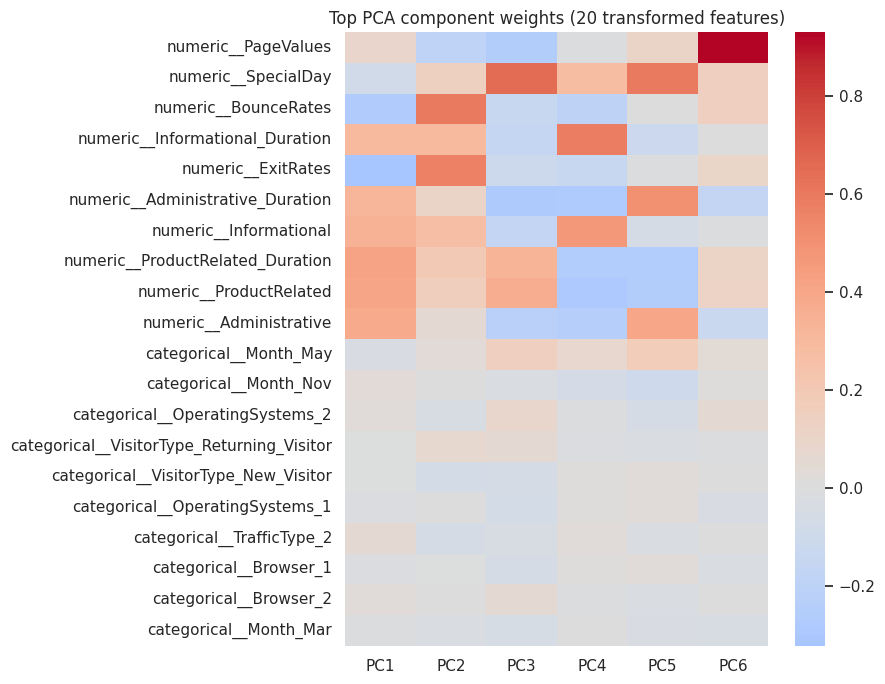

In [5]:
loadings = pd.DataFrame(PCA_6.components_.T,
                        index=mixed_features,
                        columns=[f'PC{i+1}' for i in range(6)])
print('Top 8 features (by absolute component weight):')
for component in loadings.columns:
    display(loadings[component].reindex(loadings[component].abs().sort_values(ascending=False).head(8).index).to_frame())

plt.figure(figsize=(9, 7))
sns.heatmap(loadings.loc[loadings.abs().max(axis=1).nlargest(20).index],
            cmap='coolwarm', center=0)
plt.title('Top PCA component weights (20 transformed features)')
plt.tight_layout()
plt.show()

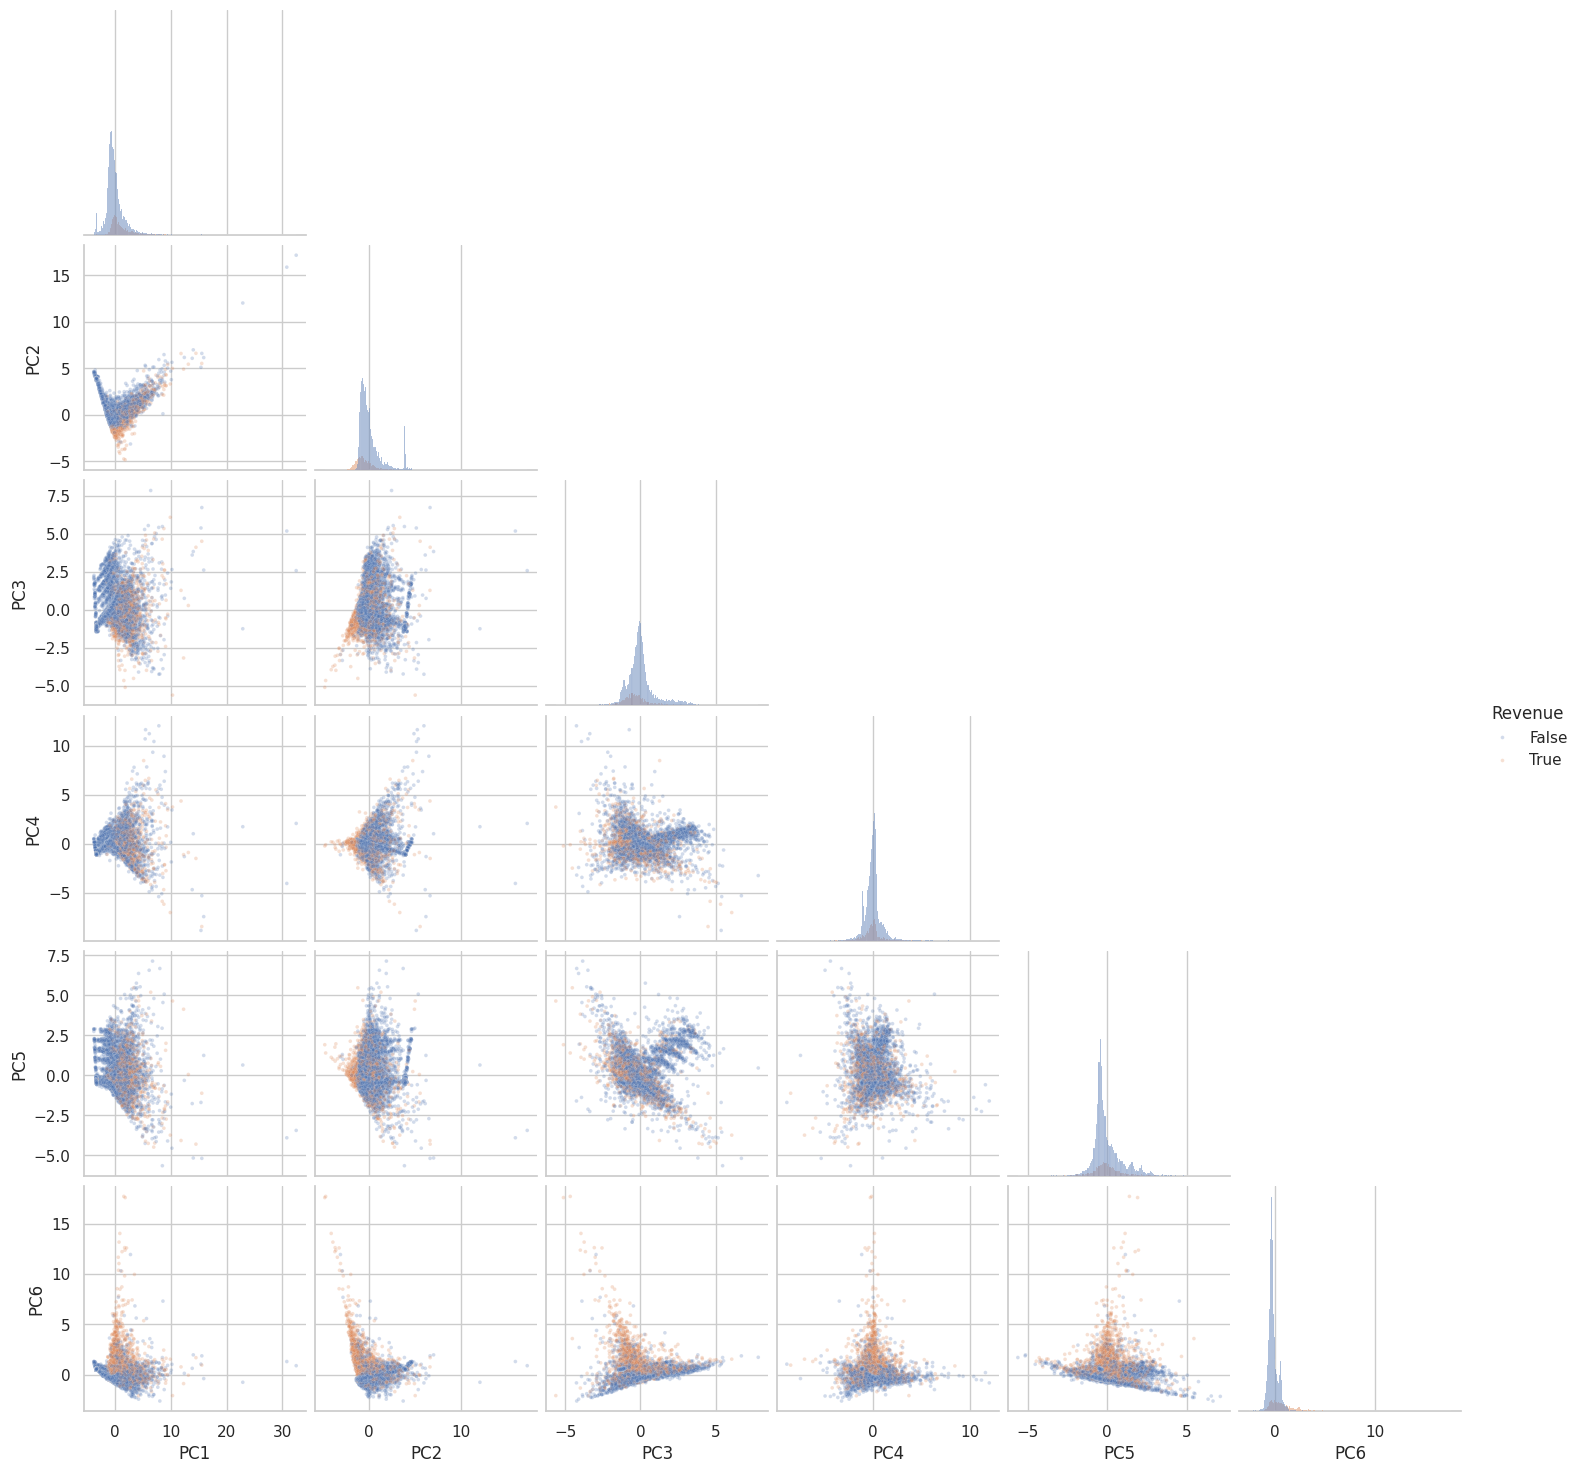

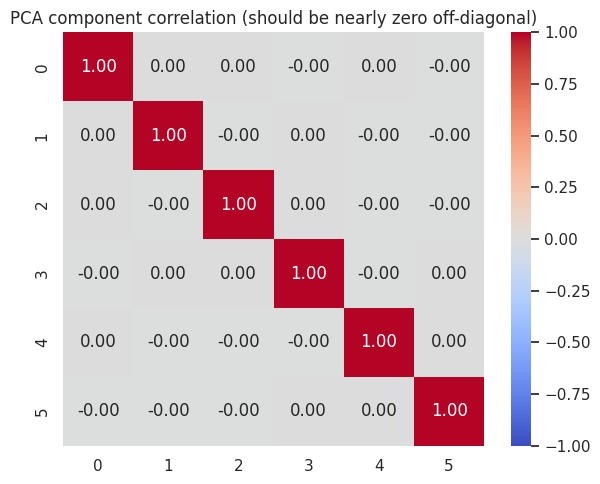

In [6]:
pca_plot = pd.DataFrame(X_PCA_6, columns=[f'PC{i+1}' for i in range(6)])
pca_plot[TARGET] = y.astype(str).to_numpy()
sns.pairplot(pca_plot, vars=[f'PC{i+1}' for i in range(6)], hue=TARGET,
             corner=True, diag_kind='hist',
             plot_kws={'alpha': 0.25, 's': 7})
plt.show()

plt.figure(figsize=(6, 5))
sns.heatmap(pd.DataFrame(X_PCA_6).corr(), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1)
plt.title('PCA component correlation (should be nearly zero off-diagonal)')
plt.tight_layout()
plt.show()

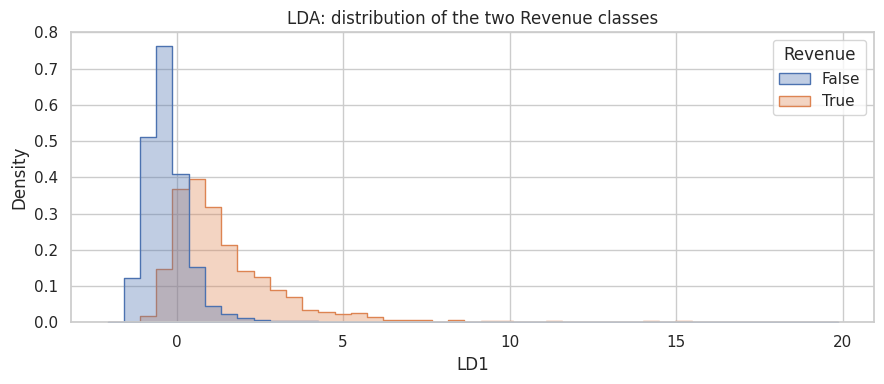

In [7]:
lda_plot = pd.DataFrame({'LD1': X_LDA_1[:, 0], TARGET: y.astype(str).to_numpy()})
plt.figure(figsize=(9, 4))
sns.histplot(data=lda_plot, x='LD1', hue=TARGET, stat='density',
             common_norm=False, bins=45, element='step', alpha=.35)
plt.title('LDA: distribution of the two Revenue classes')
plt.tight_layout()
plt.show()

**Interpretation:** PCA is unsupervised: the largest-variance axes need not separate the labels. LDA uses `Revenue` and produces **only one** axis for this binary target; its `explained_variance_ratio_ = [1]` describes the fraction of **discriminant variance**, **not** retention of 100% of total input variance. The LDA plot is **in-sample exploratory visualization**, not a generalization result.

### 2.2.3 TruncatedSVD and SelectKBest on binary-encoded input

TruncatedSVD extracts real-valued components from the binary indicator space, whereas SelectKBest(`chi2`) preserves the original 0/1 columns. The selection below is **supervised and exploratory** (it uses `Revenue`); for held-out evaluation, fit it only on each training split.

In [8]:
SVD_6 = TruncatedSVD(n_components=6, random_state=RANDOM_STATE)
X_SVD_6 = SVD_6.fit_transform(X_binary)
print('SVD reduced shape:', X_SVD_6.shape)
svd_variance = pd.DataFrame({
    'Component': [f'SVD{i+1}' for i in range(6)],
    'Variance': SVD_6.explained_variance_,
    'Explained ratio': SVD_6.explained_variance_ratio_,
    'Cumulative ratio': np.cumsum(SVD_6.explained_variance_ratio_),
})
display(svd_variance)

SVD reduced shape: (12205, 6)


,Component,Variance,Explained ratio,Cumulative ratio
0,SVD1,0.0585,0.0111,0.0111
1,SVD2,0.5343,0.1011,0.1122
2,SVD3,0.4415,0.0835,0.1957
3,SVD4,0.3663,0.0693,0.2650
4,SVD5,0.3022,0.0572,0.3221
5,SVD6,0.2875,0.0544,0.3765


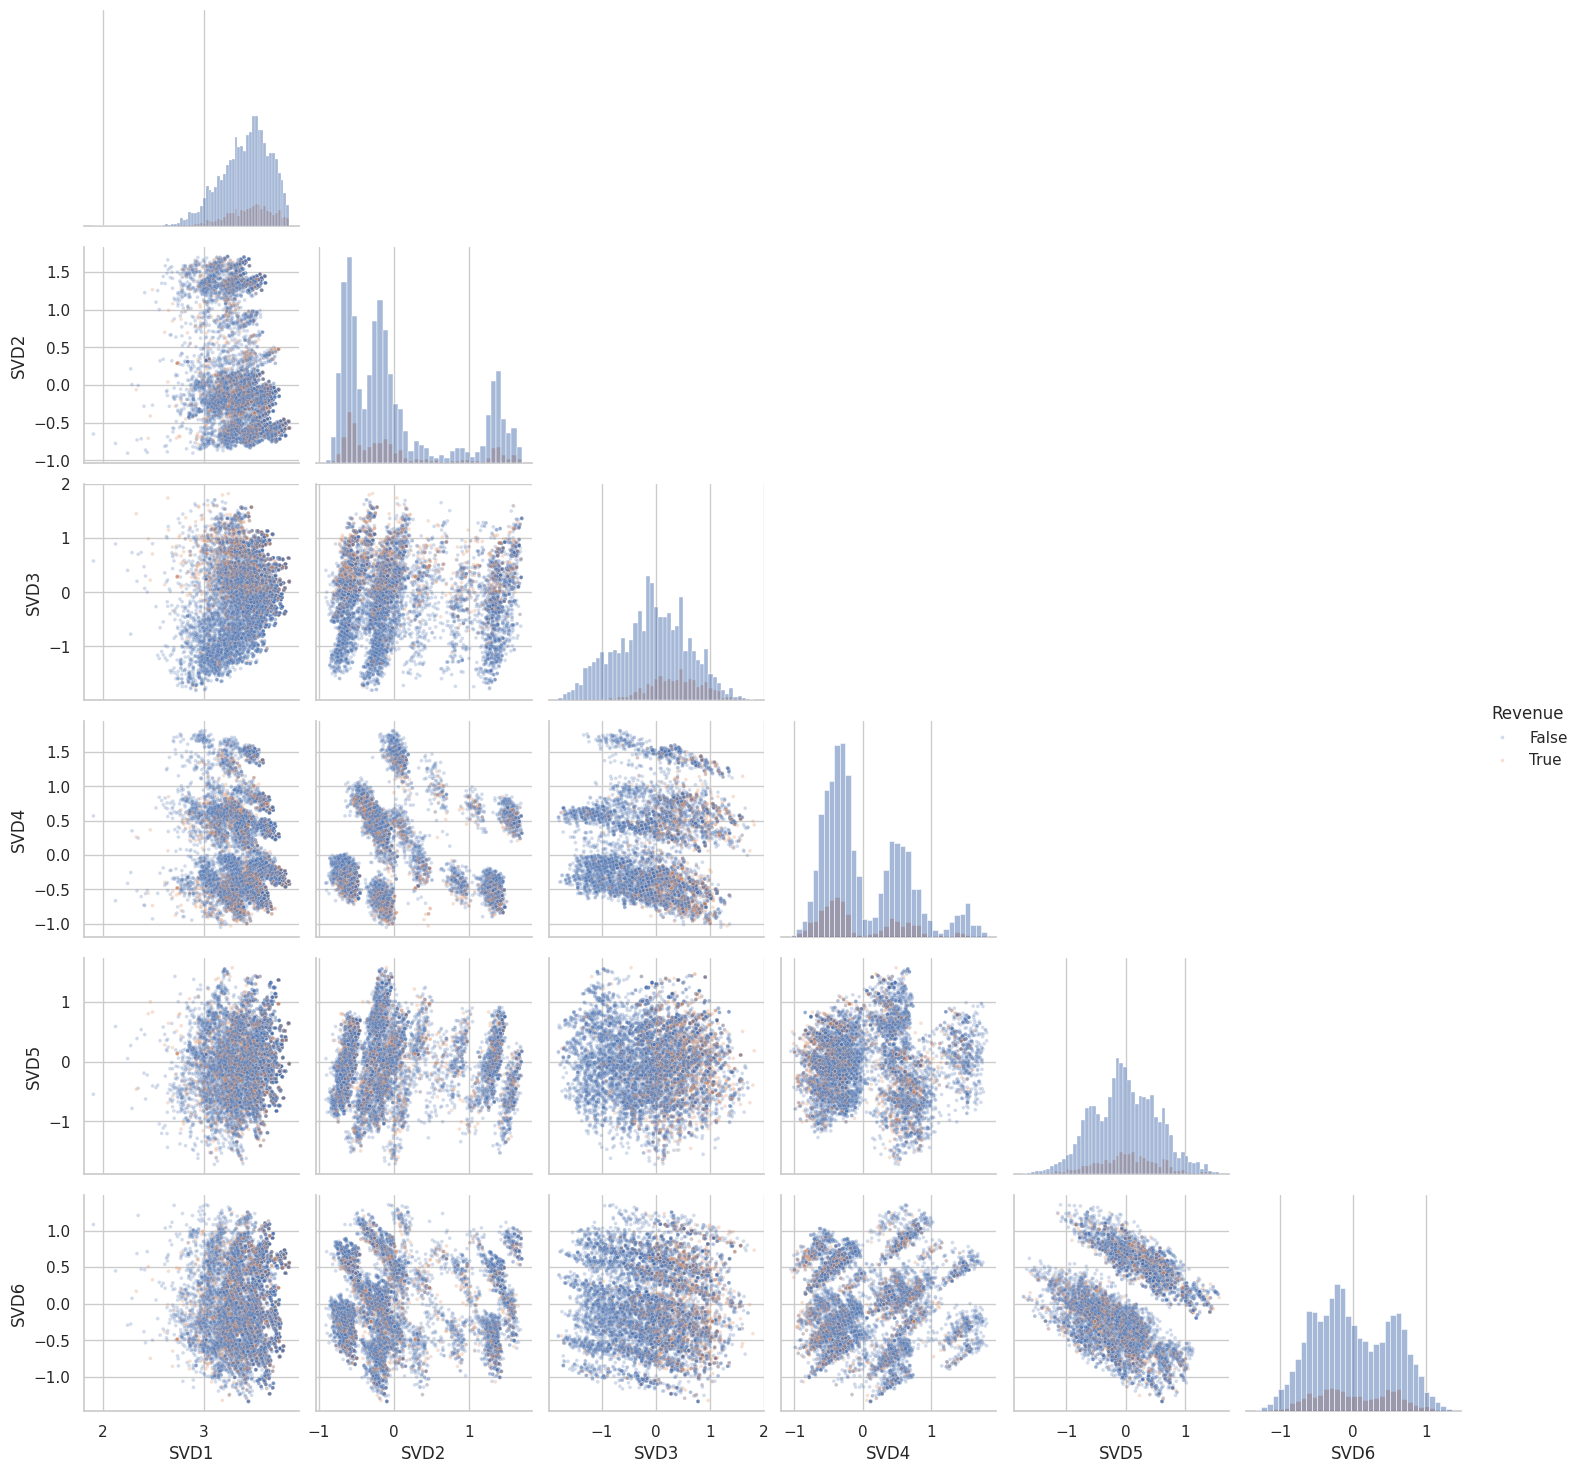

In [9]:
svd_plot = pd.DataFrame(X_SVD_6, columns=[f'SVD{i+1}' for i in range(6)])
svd_plot[TARGET] = y.astype(str).to_numpy()
sns.pairplot(svd_plot, vars=[f'SVD{i+1}' for i in range(6)], hue=TARGET,
             corner=True, diag_kind='hist',
             plot_kws={'alpha': 0.25, 's': 7})
plt.show()

Binary input: (12205, 105)
SelectKBest output: (12205, 20)
Binary values preserved: True


,Selected feature,Chi-square score,p-value
0,numeric__PageValues_1.0,350.2973,0.0000
1,categorical__Month_Nov,219.5122,0.0000
2,numeric__ExitRates_1.0,145.3950,0.0000
3,numeric__ExitRates_0.0,118.9774,0.0000
4,numeric__ExitRates_3.0,116.3983,0.0000
5,categorical__VisitorType_New_Visitor,110.8605,0.0000
6,numeric__ExitRates_2.0,110.5452,0.0000
7,categorical__TrafficType_2,107.6053,0.0000
8,numeric__BounceRates_3.0,103.4395,0.0000
9,numeric__Administrative_1.0,70.2112,0.0000


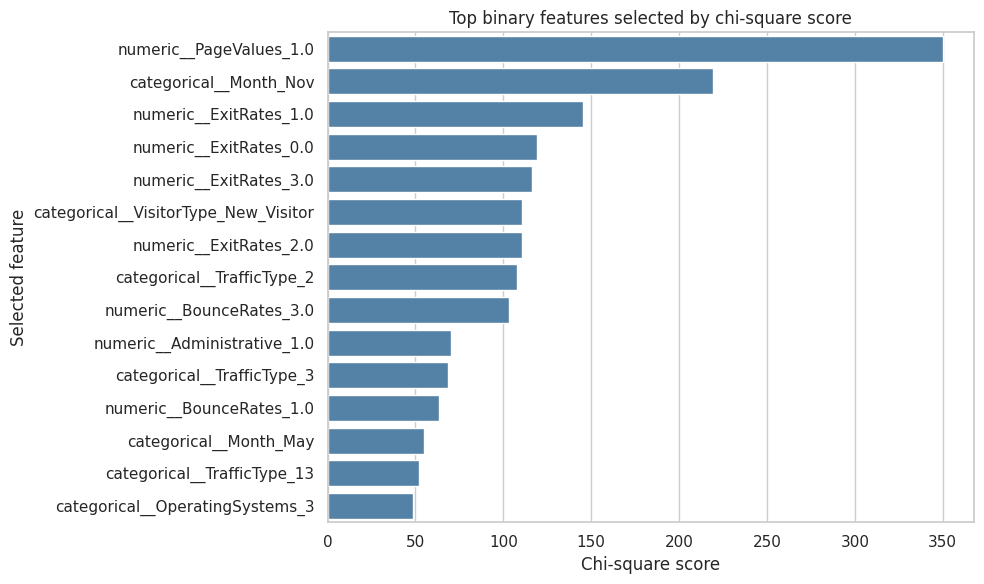

In [10]:
# Exploratory supervised selection from the full binary indicator representation.
K_BEST_BINARY = min(20, X_binary.shape[1])
kbest_binary = SelectKBest(score_func=chi2, k=K_BEST_BINARY)
X_KBest_binary = kbest_binary.fit_transform(X_binary, y)

selected_feature_names = np.asarray(binary_features)[kbest_binary.get_support()]
selected_scores = kbest_binary.scores_[kbest_binary.get_support()]
selected_pvalues = kbest_binary.pvalues_[kbest_binary.get_support()]

kbest_features_df = (pd.DataFrame({
    'Selected feature': selected_feature_names,
    'Chi-square score': selected_scores,
    'p-value': selected_pvalues,
}).sort_values('Chi-square score', ascending=False).reset_index(drop=True))

print('Binary input:', X_binary.shape)
print('SelectKBest output:', X_KBest_binary.shape)
print('Binary values preserved:',
      set(np.unique(X_KBest_binary.data if sparse.issparse(X_KBest_binary)
                    else X_KBest_binary)).issubset({0, 1}))
display(kbest_features_df)

plt.figure(figsize=(10, 6))
sns.barplot(data=kbest_features_df.head(15),
            x='Chi-square score', y='Selected feature', color='steelblue')
plt.title('Top binary features selected by chi-square score')
plt.tight_layout()
plt.show()


**Interpretation:** TruncatedSVD can operate without centering and efficiently handles sparse one-hot input. Its components are continuous, while SelectKBest(`chi2`) selects original binary columns and retains their 0/1 values. Unlike PCA/SVD, SelectKBest does **not** provide an explained-variance ratio; chi-square scores measure each feature's association with the class label. This exploratory feature ranking must not be reused directly for held-out evaluation.

### 2.2.4 Information retained, number of components, and selected features

,Target variance,PCA components,SVD components
0,80%,12,22
1,90%,20,33
2,95%,28,42


Input features: PCA/mixed = 75 ; SVD/binary = 105
Six-component variance: PCA = 0.6464 ; SVD = 0.3765
SelectKBest(binary): 105 input columns -> 20 selected columns
SelectKBest(binary) retained feature fraction: 0.1905


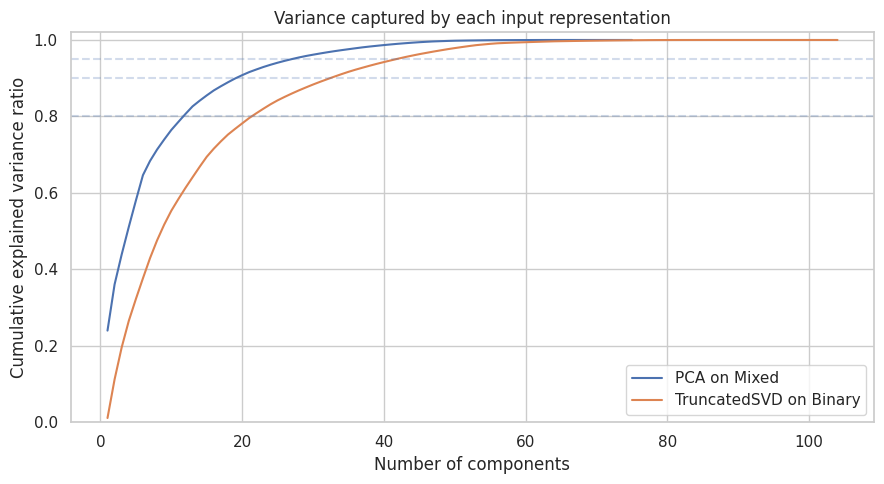

In [11]:
# PCA full spectrum. Results are for the exploratory full dataset.
pca_full = PCA(svd_solver='full').fit(X_mixed)
pca_cum = np.cumsum(pca_full.explained_variance_ratio_)

# Fit up to min(n_samples, n_features)-1 components for TruncatedSVD.
# For large matrices, use fewer components or randomized algorithm with a seed.
svd_full = TruncatedSVD(n_components=min(X_binary.shape)-1,
                        random_state=RANDOM_STATE, algorithm='randomized', n_iter=10)
svd_full.fit(X_binary)
svd_cum = np.cumsum(svd_full.explained_variance_ratio_)

thresholds = [0.80, 0.90, 0.95]
def dims_to_reach(cumulative, threshold):
    index = np.searchsorted(cumulative, threshold)
    return int(index + 1) if index < len(cumulative) else None

summary = pd.DataFrame({
    'Target variance': [f'{x:.0%}' for x in thresholds],
    'PCA components': [dims_to_reach(pca_cum, t) for t in thresholds],
    'SVD components': [dims_to_reach(svd_cum, t) for t in thresholds],
})
display(summary)

print('Input features: PCA/mixed =', X_mixed.shape[1],
      '; SVD/binary =', X_binary.shape[1])
print('Six-component variance: PCA =', round(pca_cum[5], 4),
      '; SVD =', round(svd_cum[5], 4))
print('SelectKBest(binary):', X_binary.shape[1], 'input columns ->',
      X_KBest_binary.shape[1], 'selected columns')
print('SelectKBest(binary) retained feature fraction:',
      round(X_KBest_binary.shape[1] / X_binary.shape[1], 4))

plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, len(pca_cum)+1), pca_cum, label='PCA on Mixed')
plt.plot(np.arange(1, len(svd_cum)+1), svd_cum, label='TruncatedSVD on Binary')
for level in thresholds:
    plt.axhline(level, linestyle='--', alpha=.25)
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance ratio')
plt.ylim(0, 1.02)
plt.legend()
plt.title('Variance captured by each input representation')
plt.tight_layout()
plt.show()

**Important correction:** Recomputing from the current cleaned CSV and the current pipelines gives **PCA: 12/20/28 components** and **SVD: 22/33/42 components** for **80%/90%/95%** respectively. The old saved notebook output stating PCA 21/32/41 was inconsistent with this clean rerun (likely stale notebook state). Always use the freshly executed `summary` table. PCA (centered) and TruncatedSVD (uncentered) are applied to **different encodings**, so variance-ratio curves are not controlled comparisons of algorithms. Use a held-out classification metric to assess predictive value.

**SelectKBest is not included in the explained-variance plot** because it does not construct orthogonal components or report explained variance. Instead, its retained column count and selected-feature chi-square scores are shown above. A high chi-square score is an in-sample association, not predictive validation performance.

### 2.2.5 Class-label relationship and final method comparison

In [12]:
# Exploratory, IN-SAMPLE univariate rank discrimination only;
# values >0.5 do NOT constitute validation accuracy.
rows = []
for name, scores in [('PCA', X_PCA_6), ('SVD', X_SVD_6), ('LDA', X_LDA_1)]:
    for j in range(scores.shape[1]):
        auc = roc_auc_score(y, scores[:, j])
        rows.append({'Method': name, 'Component': j + 1,
                     'In-sample univariate AUC (orientation-adjusted)': max(auc, 1-auc)})
display(pd.DataFrame(rows))

# SelectKBest retains individual indicator columns rather than continuous components.
# The following AUC scores are also in-sample exploratory associations.
selected_auc = []
for j, feature in enumerate(selected_feature_names):
    values = X_KBest_binary[:, j]
    if sparse.issparse(values):
        values = values.toarray().ravel()
    else:
        values = np.asarray(values).ravel()
    auc = roc_auc_score(y, values)
    selected_auc.append({
        'Method': 'SelectKBest (binary)', 'Feature': feature,
        'In-sample univariate AUC (orientation-adjusted)': max(auc, 1 - auc)
    })
display(pd.DataFrame(selected_auc).sort_values(
    'In-sample univariate AUC (orientation-adjusted)', ascending=False).head(10))


,Method,Component,In-sample univariate AUC (orientation-adjusted)
0,PCA,1,0.7201
1,PCA,2,0.6478
2,PCA,3,0.6128
3,PCA,4,0.5315
4,PCA,5,0.5338
5,PCA,6,0.7684
6,SVD,1,0.5426
7,SVD,2,0.5015
8,SVD,3,0.6970
9,SVD,4,0.5558


,Method,Feature,In-sample univariate AUC (orientation-adjusted)
4,SelectKBest (binary),numeric__ExitRates_0.0,0.6179
13,SelectKBest (binary),categorical__Month_Nov,0.5913
16,SelectKBest (binary),categorical__TrafficType_2,0.5732
5,SelectKBest (binary),numeric__ExitRates_1.0,0.5560
19,SelectKBest (binary),categorical__VisitorType_New_Visitor,0.5489
12,SelectKBest (binary),categorical__Month_May,0.5483
17,SelectKBest (binary),categorical__TrafficType_3,0.5418
14,SelectKBest (binary),categorical__OperatingSystems_3,0.5396
15,SelectKBest (binary),categorical__TrafficType_1,0.5346
0,SelectKBest (binary),numeric__Administrative_1.0,0.5334


#### Conclusions for section 2.2

- **PCA (Mixed):** the first six components retain about **64.64%** of input variance. Their scatterplots show substantial class overlap and some skewness/outliers. The axes are linearly uncorrelated on the fitted input.
- **LDA (Mixed):** uses the class labels and returns just **one** discriminant direction (two Revenue classes). Analyze separation with the LD1 histogram; do not compare its `[1.]` discriminant ratio to PCA variance retention.
- **SelectKBest (Binary):** supervised chi-square selection retains **20 original binary features** (or fewer if the encoded input has fewer than 20); inspect the feature-score table for the selected columns. It preserves the 0/1 representation, so it remains compatible with BernoulliNB. It does not have explained variance ratio, and in-sample feature association is not a validation score.
- **TruncatedSVD (Binary):** the first six components retain about **37.65%** of the variance in the transformed binary representation. Band-like or grouped patterns appear, but positive/negative Revenue labels strongly overlap.
- **At 95% explained variance:** **PCA: 28/75** and **TruncatedSVD: 42/105** dimensions, corresponding to **62.7% vs 60.0% feature-count reduction**, respectively, on **different input representations**. Earlier saved PCA counts of 41 at 95% should not be used without reproducing them.
- **Limitations:** PCA/SVD do not optimize class separation; apparent clusters do not imply Revenue classes. A high variance-retention ratio is not necessarily a high predictive score. Use train-only fitted pipelines in §2.4.

The requirement to visualize pairs of ~4–6 components is met by PCA and SVD; SelectKBest displays selected original features instead of new components, and **LDA is necessarily 1D** in this binary problem and is displayed as a class-conditioned histogram instead.

---
## 2.3 Clustering

This section investigates whether online shopping sessions naturally form distinct groups based on their behavioral and session-related features. Two unsupervised clustering algorithms, K-Means and DBSCAN, are employed to compare centroid-based and density-based clustering approaches.

Clustering is performed without using the target variable, Revenue, to ensure that cluster formation is independent of purchase outcomes. Both the preprocessed feature space and a PCA-reduced representation are considered to examine the effects of dimensionality reduction.

This experience will use:
- **K-means**


K-Means is a centroid-based unsupervised learning algorithm that partitions data into (k) clusters by minimizing the within-cluster sum of squared distances. In this experiment, K-Means is applied to the preprocessed Online Shoppers dataset to investigate whether shopping sessions can be grouped according to similarities in user behavior.

### Selecting the Number of Clusters

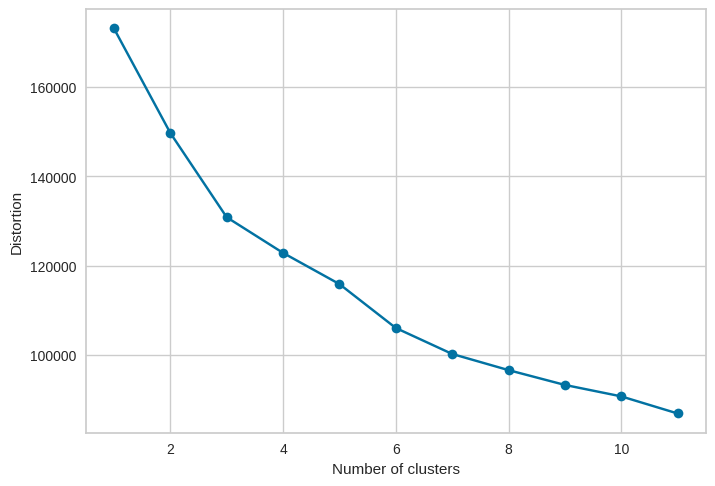

In [55]:
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import KElbowVisualizer
from yellowbrick.cluster import SilhouetteVisualizer


def elbow(X):
    distoretion = []
    for k in range(1,12):
        kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE)
        kmeans.fit(X)
        distoretion.append(kmeans.inertia_)
    plt.plot(range(1,12), distoretion, marker='o')
    plt.xlabel('Number of clusters')
    plt.ylabel('Distortion')
    plt.show()

elbow(X_mixed)


Silhouette Score for k=2: 0.30143429105724995
Silhouette Score for k=3: 0.2913494368880274
Silhouette Score for k=4: 0.185862845816872
Silhouette Score for k=5: 0.18912148544140336
Silhouette Score for k=6: 0.2084506621235744
Silhouette Score for k=7: 0.21132831862646037


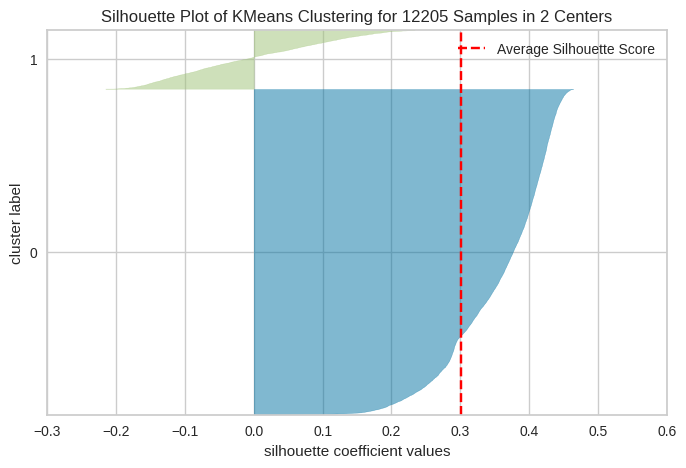

2

In [81]:
def silhouette(X):
    max_score = 0
    best_k = 0
    best = None
    for k in [2, 3, 4, 5, 6, 7]:
        kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE)
        kmeans.fit(X)
        score = silhouette_score(X, kmeans.labels_)
        if score > max_score:
            max_score = score
            best_k = k
            best = kmeans
        print(f"Silhouette Score for k={k}: {score}")
    plt.figure(figsize=(8, 5))
    visualizer = SilhouetteVisualizer(best, colors='yellowbrick')
    visualizer.fit(X)
    visualizer.show()
    return best_k

silhouette(X_mixed)

### K-Means: Selection of the Number of Clusters

The Elbow Method indicates a gradual reduction in inertia without a clearly defined optimal cluster count. Therefore, Silhouette Scores were evaluated for k values from 2 to 7.

The highest Silhouette Score was obtained at k=2 (0.3014), followed closely by k=3 (0.2913). Increasing the number of clusters beyond three substantially reduced the Silhouette Score, suggesting weaker cluster separation.

Based on these results, k=2 is selected as the primary configuration. However, k=3 remains a reasonable alternative for further interpretation.

In [80]:
for k in (2,3):
    kmeans = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_mixed)

    cluster_analysis = pd.DataFrame({
        'Cluster': cluster_labels,
        'Revenue': np.asarray(y).astype(int)
    })

    summary = cluster_analysis.groupby('Cluster').agg(
        Size=('Revenue', 'size'),
        Purchases=('Revenue', 'sum'),
        Purchase_Rate=('Revenue', 'mean')
    )

    summary['Purchase_Rate'] *= 100
    print(f'Cluster analysis for k={k}')
    display(summary)

Cluster analysis for k=2


,Size,Purchases,Purchase_Rate
Cluster,,,
0,10356,1389,13.4125
1,1849,519,28.0692


Cluster analysis for k=3


,Size,Purchases,Purchase_Rate
Cluster,,,
0,9633,1442,14.9694
1,1628,460,28.2555
2,944,6,0.6356


### K-Means: Cluster Interpretation

Although k=2 achieves the highest Silhouette Score (0.3014), k=3 provides additional insights into purchasing behavior with only a slight reduction in clustering quality (0.2913).

For k=3, the clusters exhibit substantially different purchase rates. Cluster 1 has the highest purchase rate (28.26%), while Cluster 0 remains close to the overall dataset average (14.97%). Notably, Cluster 2 contains 944 sessions but only six purchases, resulting in a purchase rate of 0.64%.

These findings suggest that K-Means can identify groups associated with different purchasing tendencies, even without using Revenue during clustering. While k=2 provides slightly better separation, k=3 offers a more detailed segmentation of shopping sessions. We will analyze cluster relationship with input features and Revenue.

In [86]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
labels = kmeans.fit_predict(X_mixed)

# Khoảng cách bình phương từ mỗi mẫu đến tâm cụm của nó
distances = kmeans.transform(X_mixed)
squared_distances = distances[
    np.arange(len(labels)), labels
] ** 2

input_summary = pd.DataFrame({
    'Cluster': labels,
    'Squared_Distance': squared_distances
}).groupby('Cluster').agg(
    Size=('Squared_Distance', 'size'),
    Mean_Squared_Distance=('Squared_Distance', 'mean'),
    Total_Inertia=('Squared_Distance', 'sum')
)

display(input_summary)

print('Silhouette Score:',
      silhouette_score(
          X_mixed, labels,
          random_state=RANDOM_STATE
      ))

,Size,Mean_Squared_Distance,Total_Inertia
Cluster,,,
0,1628,27.1704,44233.3403
1,9633,8.2275,79255.8116
2,944,7.7792,7343.5392


Silhouette Score: 0.2913494368880274


In [87]:
X_analysis = X.reset_index(drop=True).copy()
X_analysis['Cluster'] = labels

features = [
    'Administrative',
    'Administrative_Duration',
    'Informational',
    'Informational_Duration',
    'ProductRelated',
    'ProductRelated_Duration',
    'BounceRates',
    'ExitRates',
    'PageValues',
    'SpecialDay'
]

# Giá trị trung bình từng đặc trưng theo cụm
cluster_means = X_analysis.groupby('Cluster')[features].mean()

# So sánh với mức trung bình toàn bộ dữ liệu
overall_means = X_analysis[features].mean()

display(cluster_means.round(3))

# Độ lệch so với trung bình toàn dataset
relative_difference = (
    cluster_means - overall_means
) / overall_means.replace(0, np.nan)

display(relative_difference.round(2))

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
Cluster,,,,,,,,,,
0,7.3650,308.5720,2.5150,212.2430,96.8250,3835.1860,0.0060,0.0190,9.7480,0.0300
1,1.7130,51.1240,0.2180,8.2450,23.9000,874.3380,0.0090,0.0320,5.8910,0.0610
2,0.0600,1.7570,0.0170,0.0970,3.4530,68.9020,0.1600,0.1760,0.0000,0.1260


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
Cluster,,,,,,,,,,
0,2.1500,2.7800,3.9400,5.0900,2.0200,2.1800,-0.6900,-0.5300,0.6400,-0.5200
1,-0.2700,-0.3700,-0.5700,-0.7600,-0.2500,-0.2800,-0.5600,-0.2300,-0.0100,-0.0100
2,-0.9700,-0.9800,-0.9700,-1.0000,-0.8900,-0.9400,6.8600,3.2500,-1.0000,1.0300


In [88]:
from scipy.stats import chi2_contingency

output_analysis = pd.DataFrame({
    'Cluster': labels,
    'Revenue': np.asarray(y).astype(int)
})

# Bảng số lượng True/False theo cụm
contingency = pd.crosstab(
    output_analysis['Cluster'],
    output_analysis['Revenue']
)

display(contingency)

# Chi-square independence test
chi2, p_value, dof, expected = chi2_contingency(contingency)

# Cramer's V
n = contingency.to_numpy().sum()
r, c = contingency.shape

cramers_v = np.sqrt(
    chi2 / (n * min(r - 1, c - 1))
)

print(f'Chi-square: {chi2:.4f}')
print(f'p-value: {p_value:.6g}')
print(f"Cramer's V: {cramers_v:.4f}")

Revenue,0,1
Cluster,,
0,1168,460
1,8191,1442
2,938,6


Chi-square: 360.8715
p-value: 4.34256e-79
Cramer's V: 0.1720


### K-Means: Quantitative Cluster Analysis (k = 3)

The K-Means results reveal three behavioral groups with distinct levels of engagement. Cluster 0 (1,628 sessions) exhibits the highest activity, averaging 96.83 product-related pages and 3,835 seconds of product browsing, but also has the largest within-cluster mean squared distance (27.17). Cluster 1 represents moderate engagement, while Cluster 2 (944 sessions) shows minimal browsing activity, high bounce and exit rates, and an average PageValues of zero.

The overall Silhouette Score of 0.2913 indicates limited cluster separation, although the clusters exhibit meaningful differences in their behavioral characteristics.

Revenue distributions also differ substantially across clusters. The high-engagement cluster achieves a purchase rate of 28.26%, compared with 14.97% for the moderate-engagement cluster and only 0.64% for the low-engagement cluster.

The Chi-square test confirms a statistically significant association between cluster membership and Revenue (χ² = 360.87, p < 0.001). However, Cramér's V of 0.172 indicates a relatively weak overall association.

These findings suggest that K-Means identifies behavioral segments associated with different purchasing tendencies, even though Revenue was excluded from clustering. Nevertheless, the moderate-to-low Silhouette Score and relatively weak association strength indicate that the clusters should not be interpreted as clearly separated purchasing classes.

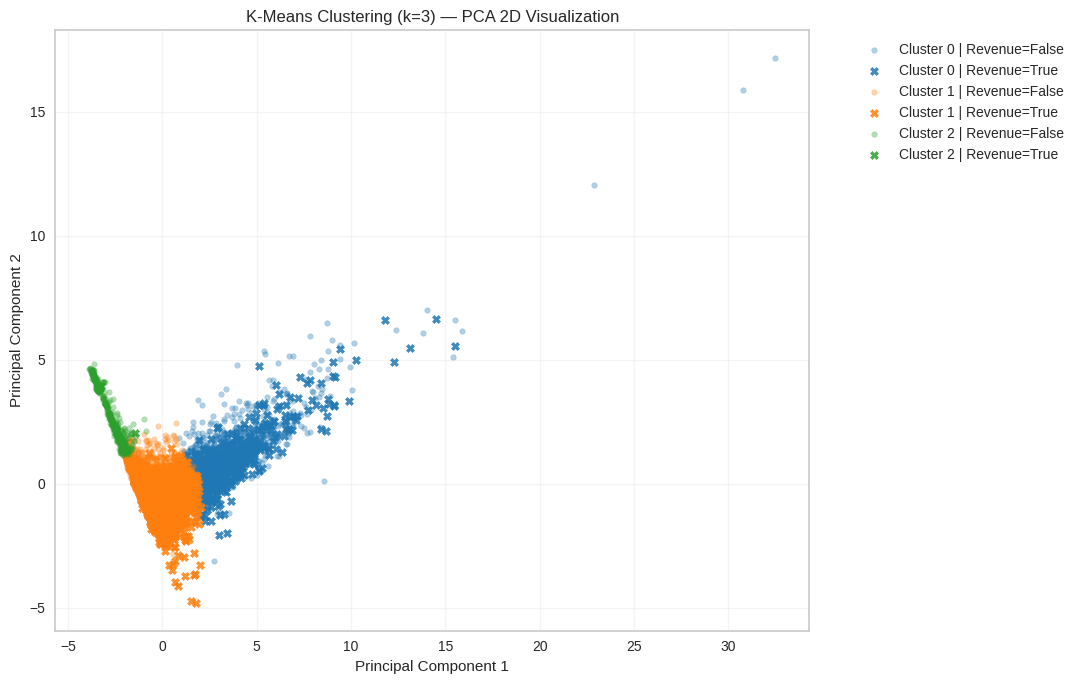

In [90]:
# PCA for display only
pca_vis = PCA(n_components=2, random_state=42)
X_2d = pca_vis.fit_transform(X_mixed)

cluster_labels = np.asarray(labels)
revenue_labels = np.asarray(y).astype(bool)

fig, ax = plt.subplots(figsize=(11, 7))

colors = {
    0: 'tab:blue',
    1: 'tab:orange',
    2: 'tab:green'
}

markers = {
    False: 'o',
    True: 'X'
}

for cluster in np.unique(cluster_labels):
    for revenue in [False, True]:

        mask = (
            (cluster_labels == cluster)
            & (revenue_labels == revenue)
        )

        ax.scatter(
            X_2d[mask, 0],
            X_2d[mask, 1],
            c=colors[cluster],
            marker=markers[revenue],
            s=16 if not revenue else 35,
            alpha=0.35 if not revenue else 0.85,
            label=f'Cluster {cluster} | Revenue={revenue}',
            rasterized=True
        )

ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_title('K-Means Clustering (k=3) — PCA 2D Visualization')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

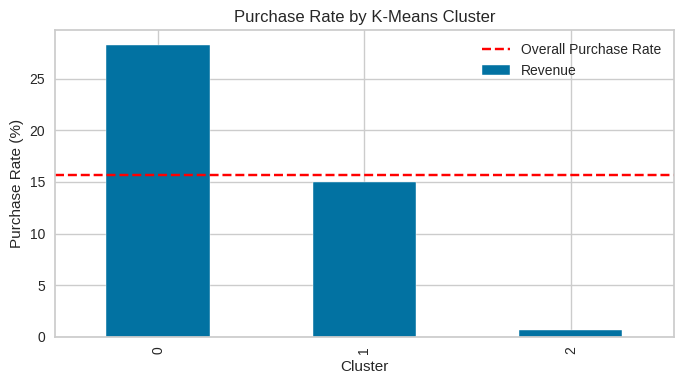

In [91]:
cluster_df = pd.DataFrame({
    'Cluster': labels,
    'Revenue': np.asarray(y).astype(int)
})

purchase_rate = (
    cluster_df.groupby('Cluster')['Revenue'].mean() * 100
)

ax = purchase_rate.plot(
    kind='bar',
    figsize=(7, 4)
)

ax.axhline(
    cluster_df['Revenue'].mean() * 100,
    color='red',
    linestyle='--',
    label='Overall Purchase Rate'
)

ax.set_xlabel('Cluster')
ax.set_ylabel('Purchase Rate (%)')
ax.set_title('Purchase Rate by K-Means Cluster')
ax.legend()

plt.tight_layout()
plt.show()

---
## 2.4 Classification

**Models:** BernoulliNB, CategoricalNB (named `MultinomialNB` in existing experiments), GaussianNB, Logistic Regression, SVM.

**Datasets:** Full Binary, Full Discrete, Full Mixed; reduced versions including Mixed+PCA, Mixed+LDA, Binary+SVD, Binary+KBest and Discrete+KBest. All feature selection is fitted on training data during evaluation.

##2.4.1 Set up the run method

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import BernoulliNB, GaussianNB, CategoricalNB as Multi_MB
#Multi from the course is not alike the multinomial NB in sklearn but behave like categoricalNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix,
                             average_precision_score, roc_auc_score, accuracy_score,
                             f1_score, recall_score, precision_score)
from sklearn.model_selection import cross_validate, StratifiedKFold, GridSearchCV

In [15]:
datasets = {
    'Mixed+PCA': Pipeline(
        [('mixed', get_mixed_pipeline()), ('pca', PCA(n_components=6, random_state=RANDOM_STATE))]),
    'Binary+SVD': Pipeline(
        [('binary', get_full_binary_pipeline()), ('svd', TruncatedSVD(n_components=6, random_state=RANDOM_STATE))]),
    'Binary+KBest': Pipeline([
        ('binary', get_full_binary_pipeline()),
        ('selection', SelectKBest(score_func=chi2, k=20))
    ]),
    'Discrete+KBest': Pipeline([
        ('discrete', get_full_discrete_pipeline()),
        ('selection', SelectKBest(
            score_func=partial(mutual_info_classif,
                               discrete_features=True, random_state=RANDOM_STATE),
            k=10
        ))
    ]),
    'Full Discrete': Pipeline(
        [('discrete', get_full_discrete_pipeline())]),
    'Full Binary': Pipeline(
        [('binary', get_full_binary_pipeline())]),
    'Full Mixed': Pipeline(
        [('mixed', get_mixed_pipeline())]),
    'Mixed+LDA': Pipeline(
        [('mixed', get_mixed_pipeline()), ('lda', LDA(n_components=1))]),
}

models = {
    'BernoulliNB': BernoulliNB(binarize=None),
    'GaussianNB': GaussianNB(),
    'MultinomialNB': Multi_MB(),
    'LogisticRegression': LogisticRegression(max_iter=3000, random_state=RANDOM_STATE, class_weight='balanced', solver = 'liblinear',),
    'SVC': SVC(random_state=RANDOM_STATE, class_weight='balanced'),
}

TRAIN_TEST_SPLIT = {
    '4:1': 0.2,
    '6:4': 0.4,
    '7:3': 0.3
}

CV = StratifiedKFold(n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE)

def pipeline_creator(dataset: str, model: str, mp=None, dp=None, mparams=None, dparams=None):
    m = clone(models[model])
    d = clone(datasets[dataset])
    if mparams is not None:
        m.set_params(**mparams)
    if dparams is not None:
        d.set_params(**dparams)
    return Pipeline(
        [('dataset', d),
        ('model', m)]
    )

**Model compatibility:** BernoulliNB works naturally on Full Binary and Binary+KBest, which retain 0/1 columns; it is not directly suitable for continuous SVD scores when `binarize=None`. GaussianNB requires dense input (for example, Mixed+PCA or Binary+SVD). CategoricalNB/Multi_MB works with nonnegative integer categories from Full Discrete or Discrete+KBest; the discrete selection uses mutual information because the columns encode category IDs. Binary+KBest uses chi-square feature selection. All supervised selectors and LDA must be fitted **within each training pipeline** before test prediction.

In [16]:

def run_experiment(X, y, dataset, model, split, mp=None, dp=None, mparams=None, dparams=None):
    test_size = TRAIN_TEST_SPLIT[split]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=RANDOM_STATE,
        stratify=y
    )

    pipeline = pipeline_creator(dataset, model, mp=mp, dp=dp, mparams=mparams, dparams=dparams)
    pipeline.fit(X_train, y_train)

    # Predicted class labels
    y_pred = pipeline.predict(X_test)

    # Probability of Revenue=True
    y_score = pipeline.predict_proba(X_test)[:, 1]

    metrics = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'AUROC': roc_auc_score(y_test, y_score),
        'Average Precision': average_precision_score(y_test, y_score),
        'Confusion matrix': confusion_matrix(y_test, y_pred),
        'Classification report': classification_report(y_test, y_pred)
    }
    return pipeline, metrics

In [17]:
def check_overfitting(X_train, y_train, pipeline):
    scoring = {
        'Accuracy': 'accuracy',
        'F1': 'f1',
        'AUROC': 'roc_auc',
        'Average Precision': 'average_precision'
    }

    sc = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=CV,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    results = []

    for m in scoring:
        train_mean = sc[f'train_{m}'].mean()
        val_mean = sc[f'test_{m}'].mean()
        val_std = sc[f'test_{m}'].std()

        results.append({
            'Metric': m,
            'Train Mean': train_mean,
            'Validation Mean': val_mean,
            'Gap': train_mean - val_mean,
            'Validation Std': val_std
        })

    return pd.DataFrame(results)

## 2.4.2 Model Performance

### 2.4.2.a Generative Models — Naive Bayes

Three Naive Bayes variants are evaluated using the same stratified train/test splits (4:1, 6:4, and 7:3), but different feature representations to match their distributional assumptions:

- **BernoulliNB — Full Binary:** models binary features (including one-hot encoded categories and discretized numerical features).
- **CategoricalNB — Full Discrete:** models the probability of each integer-encoded category for each feature. **Note:** the experiment is named `MultinomialNB` in the code, but the imported estimator is `CategoricalNB`; it is *not* scikit-learn's `MultinomialNB`.
- **GaussianNB — Full Mixed / Mixed+PCA / Mixed+LDA:** assumes that each feature is conditionally Gaussian within each class. PCA and LDA are fitted within each training pipeline, not on the held-out test split.

The target is imbalanced: approximately **84.4%** of the samples are `Revenue=False`. Consequently, accuracy alone is insufficient. Particular attention is paid to **precision, recall, and F1-score for `Revenue=True`**, as this is the purchasing class and **AUROC, Average Precision**. The results below use one fixed random seed per split ratio, so they do not measure variability across repeated splits.


#### BernoulliNB — Full Binary


BernoulliNB is applied to the binary representation. After TruncatedSVD, the resulting components are real-valued, so they are no longer directly compatible with `BernoulliNB(binarize=None)'. SelectKbest keeps features instead of changing them, reducing the dimension but still has the discrete data so it will be used in this model.


In [18]:
print(f'Model: BernoulliNB, Dataset: Full Binary\n')
for split in TRAIN_TEST_SPLIT:
    pl, metrics = run_experiment(X, y, 'Full Binary', 'BernoulliNB', split)
    print(f'Split: {split}')
    for m in metrics:
        print(f'\n{m}: {metrics[m]}')
    print('-' *20)


Model: BernoulliNB, Dataset: Full Binary

Split: 4:1

Accuracy: 0.7615731257681279

Precision: 0.294238683127572

Recall: 0.3743455497382199

F1: 0.3294930875576037

AUROC: 0.7084317604489548

Average Precision: 0.32476830189995076

Confusion matrix: [[1716  343]
 [ 239  143]]

Classification report:               precision    recall  f1-score   support

       False       0.88      0.83      0.86      2059
        True       0.29      0.37      0.33       382

    accuracy                           0.76      2441
   macro avg       0.59      0.60      0.59      2441
weighted avg       0.79      0.76      0.77      2441

--------------------
Split: 6:4

Accuracy: 0.7558377714051618

Precision: 0.29896907216494845

Recall: 0.418086500655308

F1: 0.34863387978142074

AUROC: 0.718677980155893

Average Precision: 0.333075243239307

Confusion matrix: [[3371  748]
 [ 444  319]]

Classification report:               precision    recall  f1-score   support

       False       0.88      0.82   

In [19]:
#reduced by selectKBest
print(f'Model: BernoulliNB, Dataset: Binary+KBest\n')
for split in TRAIN_TEST_SPLIT:
    pl, metrics = run_experiment(X, y, 'Binary+KBest', 'BernoulliNB', split)
    print(f'Split: {split}')
    for m in metrics:
        print(f'\n{m}: {metrics[m]}')
    print('-' *20)

Model: BernoulliNB, Dataset: Binary+KBest

Split: 4:1

Accuracy: 0.7890208930766079

Precision: 0.3126760563380282

Recall: 0.2905759162303665

F1: 0.3012211668928087

AUROC: 0.7056721989274517

Average Precision: 0.3185449783156339

Confusion matrix: [[1815  244]
 [ 271  111]]

Classification report:               precision    recall  f1-score   support

       False       0.87      0.88      0.88      2059
        True       0.31      0.29      0.30       382

    accuracy                           0.79      2441
   macro avg       0.59      0.59      0.59      2441
weighted avg       0.78      0.79      0.79      2441

--------------------
Split: 6:4

Accuracy: 0.774682507169193

Precision: 0.30153121319199055

Recall: 0.33551769331585846

F1: 0.3176178660049628

AUROC: 0.7078664323530918

Average Precision: 0.3174583945876352

Confusion matrix: [[3526  593]
 [ 507  256]]

Classification report:               precision    recall  f1-score   support

       False       0.87      0.86

### BernoulliNB: Initial Performance Analysis

BernoulliNB shows relatively stable performance across all three train-test splits. On the Full Binary dataset, accuracy ranges from 75.58% to 76.16%, while the positive-class F1-score remains between 0.329 and 0.349.

After applying SelectKBest, accuracy improves to 77.47%–78.90%, mainly due to fewer false positives. However, recall and F1-score decrease across all splits, indicating that the model misses more purchasing sessions. AUROC and Average Precision also decline slightly, suggesting that feature selection has not improved the model's discriminative performance under the current configuration.

Overall, Full Binary performs better in identifying purchasing sessions, while SelectKBest provides higher overall accuracy. Further cross-validation and hyperparameter tuning are necessary to assess overfitting and determine whether feature selection can be improved.

In [20]:
for split in TRAIN_TEST_SPLIT:
    for dataset in ['Binary+KBest', 'Full Binary']:
        pipeline, metric = run_experiment(X, y, dataset, 'BernoulliNB', split)
        X_train, x_test, y_train, y_test = train_test_split(
            X, y,
            test_size=TRAIN_TEST_SPLIT[split],
            random_state=RANDOM_STATE,
            stratify=y
        )
        pipeline = pipeline_creator(dataset, 'BernoulliNB')
        pipeline.fit(X_train, y_train)
        stats = check_overfitting(X_train, y_train, pipeline)
        print(f'Split: {split}, Dataset: {dataset}')
        display(stats)
        print('-' *20)

Split: 4:1, Dataset: Binary+KBest


,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.7966,0.7952,0.0014,0.0092
1,F1,0.3290,0.3221,0.0069,0.0156
2,AUROC,0.7358,0.7304,0.0054,0.0083
3,Average Precision,0.3420,0.3319,0.0101,0.0114


--------------------
Split: 4:1, Dataset: Full Binary


,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.7689,0.7651,0.0039,0.0045
1,F1,0.3613,0.3534,0.0079,0.0096
2,AUROC,0.7435,0.7369,0.0067,0.0085
3,Average Precision,0.3527,0.3438,0.0089,0.0149


--------------------
Split: 6:4, Dataset: Binary+KBest


,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.7990,0.7964,0.0026,0.0123
1,F1,0.3386,0.3255,0.0131,0.0373
2,AUROC,0.7425,0.7379,0.0046,0.0124
3,Average Precision,0.3513,0.3494,0.0019,0.0214


... (3 outputs left out)

,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.7959,0.7939,0.0020,0.0076
1,F1,0.3393,0.3363,0.0030,0.0346
2,AUROC,0.7389,0.7364,0.0025,0.0165
3,Average Precision,0.3487,0.3437,0.0050,0.0266


--------------------
Split: 7:3, Dataset: Full Binary


,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.7681,0.7664,0.0017,0.0081
1,F1,0.3647,0.3574,0.0073,0.0277
2,AUROC,0.7466,0.7391,0.0076,0.0171
3,Average Precision,0.3582,0.3451,0.0130,0.0273


--------------------


### BernoulliNB: Overfitting Analysis

The 5-fold cross-validation results show no significant evidence of overfitting for either Full Binary or Binary+KBest across all three train-test splits. The training and validation scores remain closely aligned, with F1 gaps ranging from 0.0030 to 0.0131 and AUROC gaps below 0.008.

However, both configurations achieve relatively low training F1-scores (approximately 0.33–0.37), suggesting possible underfitting or limitations in the model's decision threshold. Full Binary consistently achieves higher F1, AUROC, and Average Precision than Binary+KBest, despite having lower accuracy.

These findings suggest that further hyperparameter tuning, feature-selection adjustments, and decision-threshold analysis may be beneficial before drawing final conclusions about model performance.

In [21]:
#testing if the dataset isnt suited for Bernoulli or the model underfitting
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TRAIN_TEST_SPLIT['4:1'],
    random_state=RANDOM_STATE,
    stratify=y
)
param_grid = {
    'model__alpha': [0.001, 0.01, 0.1, 1.0, 10.0],
    'dataset__selection__k' : [20,40,60],
    'dataset__binary__preprocessor__numeric__n_bins' : [3,4,5],
}
pipeline = pipeline_creator('Binary+KBest', 'BernoulliNB', mparams={'binarize' : None})
grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring = {
    'AP': 'average_precision',
    'AUROC': 'roc_auc',
    'F1': 'f1',
    'Recall': 'recall'
    },
    cv=CV,
    n_jobs=-1,
    refit='AP',
    return_train_score=True
)


grid.fit(X_train, y_train)

print('Best parameters:', grid.best_params_)
print('Best CV AP:', grid.best_score_)

Best parameters: {'dataset__binary__preprocessor__numeric__n_bins': 5, 'dataset__selection__k': 60, 'model__alpha': 0.01}
Best CV AP: 0.38477354083720217


In [22]:
results = pd.DataFrame(grid.cv_results_)

display(
    results[[
        'param_model__alpha',
        'param_dataset__selection__k',
        'param_dataset__binary__preprocessor__numeric__n_bins',
        'mean_train_AP',
        'mean_test_AP',
        'mean_test_AUROC',
        'mean_test_F1',
        'mean_test_Recall',
        'std_test_AP'
    ]]
    .sort_values('mean_test_AP', ascending=False)
    .head(10)
)

,param_model__alpha,param_dataset__selection__k,param_dataset__binary__preprocessor__numeric__n_bins,mean_train_AP,mean_test_AP,mean_test_AUROC,mean_test_F1,mean_test_Recall,std_test_AP
41,0.0100,60,5,0.3970,0.3848,0.7522,0.3801,0.4639,0.0215
40,0.0010,60,5,0.3970,0.3848,0.7521,0.3801,0.4639,0.0215
42,0.1000,60,5,0.3968,0.3847,0.7521,0.3801,0.4639,0.0215
43,1.0000,60,5,0.3963,0.3845,0.7519,0.3793,0.4594,0.0216
44,10.0000,60,5,0.3931,0.3821,0.7504,0.3705,0.4056,0.0200
37,0.1000,40,5,0.3858,0.3752,0.7502,0.3780,0.4580,0.0222
35,0.0010,40,5,0.3860,0.3752,0.7502,0.3780,0.4580,0.0223
36,0.0100,40,5,0.3860,0.3751,0.7502,0.3780,0.4580,0.0223
38,1.0000,40,5,0.3848,0.3744,0.7501,0.3778,0.4535,0.0227
33,1.0000,20,5,0.3808,0.3725,0.7452,0.3563,0.3670,0.0179


In [23]:
grid.best_estimator_.fit(X_train, y_train)
y_pred = grid.best_estimator_.predict(X_test)
y_score = grid.best_estimator_.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print('AUROC:', roc_auc_score(y_test, y_score))
print('Average Precision:', average_precision_score(y_test, y_score))
print('Accuracy:', accuracy_score(y_test, y_pred))
print('F1:', f1_score(y_test, y_pred, zero_division=0))
print('Recall:', recall_score(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

       False       0.88      0.82      0.85      2059
        True       0.30      0.42      0.35       382

    accuracy                           0.76      2441
   macro avg       0.59      0.62      0.60      2441
weighted avg       0.79      0.76      0.77      2441

[[1688  371]
 [ 221  161]]
AUROC: 0.7131232057446685
Average Precision: 0.3343020774491328
Accuracy: 0.7574764440802949
F1: 0.3522975929978118
Recall: 0.4214659685863874


### BernoulliNB: Hyperparameter Tuning and Final Evaluation

Hyperparameter tuning improved BernoulliNB's ability to identify purchasing sessions. Compared with the baseline Binary+KBest configuration, Recall increased from 0.291 to 0.0.421, while F1-score improved from 0.301 to 0.352. Average Precision and AUROC also increased slightly, although overall accuracy decreased from 78.90% to 75.75%.

The optimized model still produces a considerable number of false positives and false negatives, indicating limited positive-class classification performance. However, the relatively small training-validation gaps observed during cross-validation suggest no substantial evidence of overfitting.

Overall, tuning improved minority-class detection but did not fully overcome the model's limitations. Further comparison with orther models will help determine whether more flexible discriminative models achieve better results.

---
#### CategoricalNB (named `MultinomialNB` in the code) — Full Discrete

This experiment uses **`sklearn.naive_bayes.CategoricalNB`**, imported as `Multi_MB`, on ordinal-encoded categorical features and discretized numerical features. It should be described as **CategoricalNB** throughout the report, even if the current dictionary key remains `MultinomialNB`. The two estimators model different data distributions and should not be treated as interchangeable. There is no general mathematical equivalence between CategoricalNB on one-hot columns and BernoulliNB.


In [24]:
print('Model: MultinomialNB, Dataset: Full Discrete\n')
for split in TRAIN_TEST_SPLIT:
    pipeline, metric = run_experiment(X, y, 'Full Discrete', 'MultinomialNB', split)
    print(f'Split: {split}')
    for m in metric:
        print(f'\n{m}: {metric[m]}')
    print('-' *20)

Model: MultinomialNB, Dataset: Full Discrete

Split: 4:1

Accuracy: 0.8181073330602212

Precision: 0.35648148148148145

Recall: 0.20157068062827224

F1: 0.25752508361204013

AUROC: 0.7185101037712099

Average Precision: 0.3330860755945136

Confusion matrix: [[1920  139]
 [ 305   77]]

Classification report:               precision    recall  f1-score   support

       False       0.86      0.93      0.90      2059
        True       0.36      0.20      0.26       382

    accuracy                           0.82      2441
   macro avg       0.61      0.57      0.58      2441
weighted avg       0.78      0.82      0.80      2441

--------------------
Split: 6:4

Accuracy: 0.8140106513723884

Precision: 0.37168141592920356

Recall: 0.27522935779816515

F1: 0.31626506024096385

AUROC: 0.7326219288105468

Average Precision: 0.3501521690814029

Confusion matrix: [[3764  355]
 [ 553  210]]

Classification report:               precision    recall  f1-score   support

       False       0.87  

In [25]:
print('Model: MultinomialNB, Dataset: Full Discrete\n')
for split in TRAIN_TEST_SPLIT:
    pipeline, metric = run_experiment(X, y, 'Discrete+KBest', 'MultinomialNB', split)
    print(f'Split: {split}')
    for m in metric:
        print(f'\n{m}: {metric[m]}')
    print('-' *20)

Model: MultinomialNB, Dataset: Full Discrete

Split: 4:1

Accuracy: 0.8213846784104875

Precision: 0.36082474226804123

Recall: 0.18324607329842932

F1: 0.24305555555555555

AUROC: 0.7177027683341428

Average Precision: 0.3410663651361149

Confusion matrix: [[1935  124]
 [ 312   70]]

Classification report:               precision    recall  f1-score   support

       False       0.86      0.94      0.90      2059
        True       0.36      0.18      0.24       382

    accuracy                           0.82      2441
   macro avg       0.61      0.56      0.57      2441
weighted avg       0.78      0.82      0.80      2441

--------------------
Split: 6:4

Accuracy: 0.8187218353133962

Precision: 0.37896825396825395

Recall: 0.2503276539973788

F1: 0.3014996053670087

AUROC: 0.7310901722255685

Average Precision: 0.3624544571515751

Confusion matrix: [[3806  313]
 [ 572  191]]

Classification report:               precision    recall  f1-score   support

       False       0.87    

### CategoricalNB: Initial Performance Analysis

CategoricalNB achieves relatively stable accuracy of approximately 81–82% across all three train-test splits. However, its positive-class recall remains low (0.202–0.275), resulting in F1-scores between 0.258 and 0.316. This indicates that the model frequently misclassifies purchasing sessions as non-purchasing.

Applying SelectKBest slightly improves accuracy and Average Precision across all splits but consistently reduces recall and F1-score. This suggests that the current feature-selection configuration has not improved positive-class detection, despite modest improvements in ranking performance.

Overall, Full Discrete performs better in terms of F1-score and recall, while Discrete+KBest achieves slightly higher accuracy and Average Precision. Further cross-validation and hyperparameter tuning are required to assess model generalization and determine whether feature selection can be optimized.

In [26]:
for split in TRAIN_TEST_SPLIT:
    for dataset in ['Full Discrete', 'Discrete+KBest']:
        pipeline, metric = run_experiment(X, y, dataset, 'MultinomialNB', split)
        X_train, x_test, y_train, y_test = train_test_split(
            X, y,
            test_size=TRAIN_TEST_SPLIT[split],
            random_state=RANDOM_STATE,
            stratify=y
        )
        stats = check_overfitting(X_train, y_train, pipeline)
        print(f'Split: {split}, Dataset: {dataset}')
        display(stats)
        print('-' *20)

Split: 4:1, Dataset: Full Discrete


,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.8280,0.8236,0.0044,0.0030
1,F1,0.3463,0.3328,0.0136,0.0156
2,AUROC,0.7619,0.7521,0.0098,0.0095
3,Average Precision,0.3957,0.3775,0.0182,0.0193


--------------------
Split: 4:1, Dataset: Discrete+KBest


,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.8297,0.8271,0.0026,0.0030
1,F1,0.3369,0.3260,0.0110,0.0167
2,AUROC,0.7608,0.7540,0.0068,0.0107
3,Average Precision,0.4002,0.3896,0.0106,0.0166


--------------------
Split: 6:4, Dataset: Full Discrete


,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.8282,0.8251,0.0032,0.0110
1,F1,0.3598,0.3450,0.0148,0.0353
2,AUROC,0.7676,0.7576,0.0101,0.0177
3,Average Precision,0.3995,0.3863,0.0132,0.0411


... (3 outputs left out)

,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.8278,0.8252,0.0026,0.0105
1,F1,0.3499,0.3403,0.0097,0.0429
2,AUROC,0.7640,0.7569,0.0071,0.0223
3,Average Precision,0.3990,0.3847,0.0143,0.0326


--------------------
Split: 7:3, Dataset: Discrete+KBest


,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.8307,0.8293,0.0014,0.0087
1,F1,0.3409,0.3341,0.0068,0.0410
2,AUROC,0.7628,0.7589,0.0039,0.0226
3,Average Precision,0.4025,0.3970,0.0055,0.0429


--------------------


### CategoricalNB: Overfitting Analysis

The 5-fold cross-validation results show no significant evidence of overfitting for either Full Discrete or Discrete+KBest across all train-test splits. Training and validation scores remain closely aligned, with F1 gaps below 0.015 and Average Precision gaps below 0.019.

However, the relatively low F1-scores on both training and validation sets (approximately 0.33–0.36) suggest possible underfitting or limitations in positive-class detection.

SelectKBest slightly improves validation Accuracy, AUROC, and Average Precision, while F1-score improvements are inconsistent. The smaller train-validation gaps also suggest stable generalization, although the gains remain modest.

Further hyperparameter tuning is needed to determine whether discretization settings, feature selection, or smoothing parameters are limiting model performance.

In [27]:
#testing if the dataset isnt suited for Bernoulli or the model underfitting
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TRAIN_TEST_SPLIT['4:1'],
    random_state=RANDOM_STATE,
    stratify=y
)
param_grid = {
    'model__alpha': [0.001, 0.01, 0.1, 1.0, 10.0],
    'dataset__selection__k' : [5,7,9,11,13],
    'dataset__discrete__preprocessor__numeric__n_bins' : [3,4,5,6],
}
pipeline = pipeline_creator('Discrete+KBest', 'MultinomialNB')
grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring = {
    'AP': 'average_precision',
    'AUROC': 'roc_auc',
    'F1': 'f1',
    'Recall': 'recall'
    },
    cv=CV,
    n_jobs=-1,
    refit='AP',
    return_train_score=True
)


grid.fit(X_train, y_train)

print('Best parameters:', grid.best_params_)
print('Best CV AP:', grid.best_score_)

Best parameters: {'dataset__discrete__preprocessor__numeric__n_bins': 6, 'dataset__selection__k': 9, 'model__alpha': 1.0}
Best CV AP: 0.40684472934143906


In [28]:
results = pd.DataFrame(grid.cv_results_)

display(
    results[[
        'param_model__alpha',
        'param_dataset__selection__k',
        'param_dataset__discrete__preprocessor__numeric__n_bins',
        'mean_train_AP',
        'mean_test_AP',
        'mean_test_AUROC',
        'mean_test_F1',
        'mean_test_Recall',
        'std_test_AP'
    ]]
    .sort_values('mean_test_AP', ascending=False)
    .head(10)
)

,param_model__alpha,param_dataset__selection__k,param_dataset__discrete__preprocessor__numeric__n_bins,mean_train_AP,mean_test_AP,mean_test_AUROC,mean_test_F1,mean_test_Recall,std_test_AP
88,1.0000,9,6,0.4145,0.4068,0.7580,0.3709,0.3178,0.0136
87,0.1000,9,6,0.4167,0.4065,0.7581,0.3701,0.3204,0.0139
86,0.0100,9,6,0.4172,0.4064,0.7581,0.3717,0.3224,0.0138
85,0.0010,9,6,0.4173,0.4064,0.7580,0.3717,0.3224,0.0139
92,0.1000,11,6,0.4205,0.4060,0.7592,0.3730,0.3237,0.0136
93,1.0000,11,6,0.4173,0.4058,0.7598,0.3677,0.3165,0.0139
91,0.0100,11,6,0.4214,0.4057,0.7590,0.3730,0.3237,0.0132
90,0.0010,11,6,0.4214,0.4056,0.7589,0.3730,0.3237,0.0132
89,10.0000,9,6,0.4071,0.4016,0.7567,0.3232,0.2392,0.0112
97,0.1000,13,6,0.4187,0.4002,0.7593,0.3710,0.3257,0.0126


In [29]:
print('Best parameters:', grid.best_params_)

best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)
y_score = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, zero_division=0))
print(confusion_matrix(y_test, y_pred))

print('\nAUROC:', roc_auc_score(y_test, y_score))
print('Average Precision:', average_precision_score(y_test, y_score))
print('Accuracy:', accuracy_score(y_test, y_pred))
print('F1:', f1_score(y_test, y_pred, zero_division=0))
print('Recall:', recall_score(y_test, y_pred, zero_division=0))

print('-' * 30)

Best parameters: {'dataset__discrete__preprocessor__numeric__n_bins': 6, 'dataset__selection__k': 9, 'model__alpha': 1.0}
              precision    recall  f1-score   support

       False       0.87      0.93      0.90      2059
        True       0.39      0.24      0.30       382

    accuracy                           0.82      2441
   macro avg       0.63      0.59      0.60      2441
weighted avg       0.79      0.82      0.80      2441

[[1914  145]
 [ 290   92]]

AUROC: 0.7228258520249499
Average Precision: 0.3536931950682918
Accuracy: 0.8217943465792708
F1: 0.2972536348949919
Recall: 0.24083769633507854
------------------------------


### CategoricalNB: Hyperparameter Tuning Results

Hyperparameter tuning produced modest improvements in CategoricalNB's performance. Compared with the baseline Discrete+KBest configuration, the positive-class F1-score increased from 0.243 to 0.297, while Recall improved from 0.183 to 0.241. AUROC and Average Precision also increased slightly, reaching 0.723 and 0.354, respectively.

Despite these improvements, the model still misses a large proportion of purchasing sessions, with 290 false negatives among 382 positive samples. This suggests that the current preprocessing and model assumptions may limit its ability to identify the minority class.

Overall, tuning improved classification performance, but the gains remain insufficient to overcome the model's limitations. Further comparison with orther models is needed to determine whether discriminative approaches provide better results.

### Gaussian Naive Bayes (GaussianNB)

Gaussian Naive Bayes is a probabilistic classification algorithm that assumes continuous features follow a Gaussian (normal) distribution within each class. Unlike BernoulliNB and CategoricalNB, GaussianNB can directly handle continuous numerical features without requiring discretization or binarization.

In this experiment, GaussianNB is evaluated on three feature representations:

- **Full Mixed:** The original numerical features are standardized, while categorical features are one-hot encoded.
- **Mixed + PCA:** Principal Component Analysis reduces dimensionality by retaining directions with the highest variance.
- **Mixed + LDA:** Linear Discriminant Analysis projects the data onto a single component that maximizes class separability.


In [30]:
print('Model: GaussianNB, Dataset: Full mixed\n')
for split in TRAIN_TEST_SPLIT:
    pipeline, metrics = run_experiment(X, y, 'Full Mixed', 'GaussianNB', split)
    print(f'Split: {split}')
    for m in metrics:
        print(f'\n{m}: {metrics[m]}')
    print('-' *20)


Model: GaussianNB, Dataset: Full mixed

Split: 4:1

Accuracy: 0.26423596886521916

Precision: 0.17359187442289936

Recall: 0.9842931937172775

F1: 0.29513343799058084

AUROC: 0.7392503604403093

Average Precision: 0.2950363254780755

Confusion matrix: [[ 269 1790]
 [   6  376]]

Classification report:               precision    recall  f1-score   support

       False       0.98      0.13      0.23      2059
        True       0.17      0.98      0.30       382

    accuracy                           0.26      2441
   macro avg       0.58      0.56      0.26      2441
weighted avg       0.85      0.26      0.24      2441

--------------------
Split: 6:4

Accuracy: 0.2744776730848013

Precision: 0.1739028397089885

Recall: 0.9711664482306684

F1: 0.294984076433121

AUROC: 0.7146447893389232

Average Precision: 0.2651844234800824

Confusion matrix: [[ 599 3520]
 [  22  741]]

Classification report:               precision    recall  f1-score   support

       False       0.96      0.15  

In [31]:
print('Model: GaussianNB, Dataset: Mixed+PCA\n')
for split in TRAIN_TEST_SPLIT:
    pipeline, metrics = run_experiment(X, y, 'Mixed+PCA', 'GaussianNB', split)
    print(f'Split: {split}')
    for m in metrics:
        print(f'\n{m}: {metrics[m]}')
    print('-' *20)

Model: GaussianNB, Dataset: Mixed+PCA

Split: 4:1

Accuracy: 0.8672675133142155

Precision: 0.6407766990291263

Recall: 0.34554973821989526

F1: 0.4489795918367347

AUROC: 0.8328148163216526

Average Precision: 0.523652876928705

Confusion matrix: [[1985   74]
 [ 250  132]]

Classification report:               precision    recall  f1-score   support

       False       0.89      0.96      0.92      2059
        True       0.64      0.35      0.45       382

    accuracy                           0.87      2441
   macro avg       0.76      0.65      0.69      2441
weighted avg       0.85      0.87      0.85      2441

--------------------
Split: 6:4

Accuracy: 0.8691110200737403

Precision: 0.6573604060913706

Recall: 0.3394495412844037

F1: 0.44770959377700953

AUROC: 0.8421291607443943

Average Precision: 0.5425461293438952

Confusion matrix: [[3984  135]
 [ 504  259]]

Classification report:               precision    recall  f1-score   support

       False       0.89      0.97    

In [32]:
print('Model: GaussianNB, Dataset: Mixed+LDA\n')
for split in TRAIN_TEST_SPLIT:
    pipeline, metrics = run_experiment(X, y, 'Mixed+LDA', 'GaussianNB', split)
    print(f'Split: {split}')
    for m in metrics:
        print(f'\n{m}: {metrics[m]}')
    print('-' *20)

Model: GaussianNB, Dataset: Mixed+LDA

Split: 4:1

Accuracy: 0.8799672265464973

Precision: 0.7379679144385026

Recall: 0.3612565445026178

F1: 0.4850615114235501

AUROC: 0.8788945988623564

Average Precision: 0.6151396583806095

Confusion matrix: [[2010   49]
 [ 244  138]]

Classification report:               precision    recall  f1-score   support

       False       0.89      0.98      0.93      2059
        True       0.74      0.36      0.49       382

    accuracy                           0.88      2441
   macro avg       0.81      0.67      0.71      2441
weighted avg       0.87      0.88      0.86      2441

--------------------
Split: 6:4

Accuracy: 0.882425235559197

Precision: 0.7574931880108992

Recall: 0.36435124508519

F1: 0.4920353982300885

AUROC: 0.8786167226200101

Average Precision: 0.635952906704329

Confusion matrix: [[4030   89]
 [ 485  278]]

Classification report:               precision    recall  f1-score   support

       False       0.89      0.98      0.9

### GaussianNB: Initial Performance Analysis

GaussianNB performs poorly on Full Mixed data, with accuracy around 26–27% and positive-class recall exceeding 97%. The excessive number of false positives suggests that the original feature representation may violate the model's distributional and conditional independence assumptions.

Dimensionality reduction substantially improves performance. Mixed+PCA achieves approximately 86–87% accuracy, F1-scores around 0.44–0.45, and AUROC between 0.83 and 0.84. Mixed+LDA performs even better, reaching approximately 88% accuracy, F1-scores of 0.49–0.50, and AUROC around 0.879. Both methods significantly reduce false positives, with LDA providing stronger class discrimination.

However, positive-class recall remains relatively low (0.34–0.38) after dimensionality reduction, indicating that many purchasing sessions are still missed. Overall, LDA provides the most promising representation for GaussianNB, although further cross-validation and hyperparameter tuning are required to assess generalization and potential improvements.

In [33]:
for split in TRAIN_TEST_SPLIT:
    for dataset in ['Full Mixed', 'Mixed+PCA', 'Mixed+LDA']:
        pipeline, metric = run_experiment(X, y, dataset, 'GaussianNB', split)
        X_train, x_test, y_train, y_test = train_test_split(
            X, y,
            test_size=TRAIN_TEST_SPLIT[split],
            random_state=RANDOM_STATE,
            stratify=y
        )
        stats = check_overfitting(X_train, y_train, pipeline)
        print(f'Split: {split}, Dataset: {dataset}')
        display(stats)
        print('-' *20)


Split: 4:1, Dataset: Full Mixed


,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.2846,0.2827,0.0020,0.0256
1,F1,0.3013,0.2995,0.0018,0.0079
2,AUROC,0.7219,0.7094,0.0125,0.0875
3,Average Precision,0.3013,0.2955,0.0058,0.0861


--------------------
Split: 4:1, Dataset: Mixed+PCA


,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.8624,0.8622,0.0002,0.0072
1,F1,0.4284,0.4321,-0.0037,0.0253
2,AUROC,0.8511,0.8509,0.0002,0.0108
3,Average Precision,0.5237,0.5204,0.0033,0.0308


--------------------
Split: 4:1, Dataset: Mixed+LDA


,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.8827,0.8803,0.0024,0.0024
1,F1,0.5009,0.4900,0.0109,0.0161
2,AUROC,0.8887,0.8792,0.0095,0.0071
3,Average Precision,0.6443,0.6286,0.0157,0.0177


... (9 outputs left out)

,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.8619,0.8620,-0.0001,0.0073
1,F1,0.4255,0.4286,-0.0032,0.0111
2,AUROC,0.8506,0.8479,0.0027,0.0140
3,Average Precision,0.5217,0.5185,0.0032,0.0465


--------------------
Split: 7:3, Dataset: Mixed+LDA


,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.8813,0.8792,0.0021,0.0034
1,F1,0.4908,0.4806,0.0102,0.0210
2,AUROC,0.8891,0.8776,0.0115,0.0123
3,Average Precision,0.6428,0.6252,0.0177,0.0135


--------------------


### GaussianNB: Overfitting Analysis

The 5-fold cross-validation results show no substantial evidence of overfitting across the three feature representations, as training and validation scores remain closely aligned. Full Mixed consistently achieves poor classification performance despite its small train-validation gaps, suggesting limitations in the original feature representation rather than overfitting.

Both PCA and LDA substantially improve performance and maintain stable validation scores across all train-test splits. Mixed+PCA exhibits nearly zero train-validation gaps, while Mixed+LDA achieves the strongest validation results, with AUROC around 0.88 and Average Precision around 0.63.

Overall, dimensionality reduction improves GaussianNB's performance without introducing significant overfitting. Hyperparameter tuning will be conducted to investigate whether variance smoothing and the number of retained PCA components can provide further improvements.

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TRAIN_TEST_SPLIT['4:1'],
    random_state=RANDOM_STATE,
    stratify=y
)
param_grids = {
    'Full Mixed': {
        'model__var_smoothing': np.logspace(-9, 0, 10)
    },

    'Mixed+PCA': {
        'model__var_smoothing': np.logspace(-9, 0, 10),
        'dataset__pca__n_components': [3, 5, 6, 8, 10]
    },

    'Mixed+LDA': {
        'model__var_smoothing': np.logspace(-9, 0, 10)
    }
}

grid_results = {}

for m, p in param_grids.items():
    pipeline = pipeline_creator(m, 'GaussianNB')
    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=p,
        scoring = {
        'AP': 'average_precision',
        'AUROC': 'roc_auc',
        'F1': 'f1',
        'Recall': 'recall'
        },
        cv=CV,
        n_jobs=-1,
        refit='AP',
        return_train_score=True
    )
    grid.fit(X_train, y_train)

    grid_results[m] = grid

    print(f'Model: {m}')
    print('Best parameters:', grid.best_params_)
    print('Best CV AP:', grid.best_score_)
    print('-' *20)

Model: Full Mixed
Best parameters: {'model__var_smoothing': np.float64(0.1)}
Best CV AP: 0.4963250999670642
--------------------
Model: Mixed+PCA
Best parameters: {'dataset__pca__n_components': 6, 'model__var_smoothing': np.float64(1.0)}
Best CV AP: 0.5321421228086542
--------------------
Model: Mixed+LDA
Best parameters: {'model__var_smoothing': np.float64(1.0)}
Best CV AP: 0.6378689910563815
--------------------


In [35]:
for dataset, grid in grid_results.items():
    results = pd.DataFrame(grid.cv_results_)

    columns = [
        'param_model__var_smoothing',
        'mean_train_AP',
        'mean_test_AP',
        'std_test_AP',
        'mean_test_AUROC',
        'mean_test_F1',
        'mean_test_Recall'
    ]

    if dataset == 'Mixed+PCA':
        columns.insert(0, 'param_dataset__pca__n_components')

    print(f'Dataset: {dataset}')

    display(
        results[columns]
        .sort_values('mean_test_AP', ascending=False)
        .head(5)
    )

Dataset: Full Mixed


,param_model__var_smoothing,mean_train_AP,mean_test_AP,std_test_AP,mean_test_AUROC,mean_test_F1,mean_test_Recall
8,0.1000,0.4993,0.4963,0.0178,0.8301,0.5167,0.6691
7,0.0100,0.4781,0.4677,0.0229,0.8049,0.4525,0.7425
9,1.0000,0.4665,0.4674,0.0171,0.8330,0.4026,0.3224
6,0.0010,0.4291,0.4071,0.0157,0.7828,0.4214,0.7838
4,0.0000,0.4236,0.4024,0.0185,0.7799,0.3372,0.9174


Dataset: Mixed+PCA


,param_dataset__pca__n_components,param_model__var_smoothing,mean_train_AP,mean_test_AP,std_test_AP,mean_test_AUROC,mean_test_F1,mean_test_Recall
29,6,1.0000,0.5335,0.5321,0.0158,0.8598,0.0771,0.0406
39,8,1.0000,0.5318,0.5308,0.0159,0.8598,0.0771,0.0406
28,6,0.1000,0.5316,0.5291,0.0257,0.8578,0.3565,0.2451
49,10,1.0000,0.5297,0.5282,0.0162,0.8593,0.0759,0.0400
38,8,0.1000,0.5234,0.5210,0.0259,0.8566,0.3519,0.2425


Dataset: Mixed+LDA


,param_model__var_smoothing,mean_train_AP,mean_test_AP,std_test_AP,mean_test_AUROC,mean_test_F1,mean_test_Recall
9,1.0000,0.6531,0.6379,0.0180,0.8940,0.2708,0.1625
8,0.1000,0.6480,0.6322,0.0174,0.8858,0.4536,0.3257
7,0.0100,0.6448,0.6291,0.0177,0.8800,0.4866,0.3643
6,0.0010,0.6444,0.6287,0.0177,0.8793,0.4879,0.3663
5,0.0001,0.6443,0.6286,0.0177,0.8792,0.4900,0.3683


In [36]:
for dataset, grid in grid_results.items():
    print(f'Dataset: {dataset}')
    print('Best parameters:', grid.best_params_)

    best_model = grid.best_estimator_

    y_pred = best_model.predict(X_test)
    y_score = best_model.predict_proba(X_test)[:, 1]

    print(classification_report(y_test, y_pred, zero_division=0))
    print(confusion_matrix(y_test, y_pred))

    print('\nAUROC:', roc_auc_score(y_test, y_score))
    print('Average Precision:', average_precision_score(y_test, y_score))
    print('Accuracy:', accuracy_score(y_test, y_pred))
    print('F1:', f1_score(y_test, y_pred, zero_division=0))
    print('Recall:', recall_score(y_test, y_pred, zero_division=0))

    print('-' * 30)

Dataset: Full Mixed
Best parameters: {'model__var_smoothing': np.float64(0.1)}
              precision    recall  f1-score   support

       False       0.92      0.83      0.87      2059
        True       0.40      0.61      0.48       382

    accuracy                           0.79      2441
   macro avg       0.66      0.72      0.68      2441
weighted avg       0.84      0.79      0.81      2441

[[1704  355]
 [ 148  234]]

AUROC: 0.8106448766620304
Average Precision: 0.4684444736200022
Accuracy: 0.7939369111020074
F1: 0.4819773429454171
Recall: 0.612565445026178
------------------------------
Dataset: Mixed+PCA
Best parameters: {'dataset__pca__n_components': 6, 'model__var_smoothing': np.float64(1.0)}
              precision    recall  f1-score   support

       False       0.85      1.00      0.92      2059
        True       0.88      0.04      0.08       382

    accuracy                           0.85      2441
   macro avg       0.87      0.52      0.50      2441
weighted a

### GaussianNB: Hyperparameter Tuning Results

Hyperparameter tuning substantially improved GaussianNB on Full Mixed data. Increasing variance smoothing reduced false positives significantly, raising test accuracy from 0.264 to 0.794 and F1-score from 0.295 to 0.482.

However, the effects differed for dimensionality-reduced representations. For Mixed+PCA and Mixed+LDA, stronger variance smoothing substantially reduced positive-class recall and F1-score at the default decision threshold. In particular, Mixed+LDA achieved the highest AUROC (0.895) and Average Precision (0.625), despite its F1-score decreasing from 0.485 to 0.236.

These results highlight that optimizing Average Precision does not necessarily improve threshold-dependent classification metrics. Overall, variance smoothing improves ranking performance in some configurations but can substantially change classification behavior. The findings emphasize the importance of evaluating both threshold-dependent and threshold-independent metrics when comparing models.

**Thêm vào báo cáo(Xóa sau khi thêm)**

Despite achieving relatively high AUROC and Average Precision, GaussianNB with LDA exhibits low recall at the default decision threshold. This suggests that the model retains useful ranking ability, but its predicted probabilities rarely exceed the threshold required for positive classification. Lowering the threshold could improve recall at the expense of potentially increasing false positives. Threshold optimization was not performed to maintain a consistent evaluation procedure across models.

### 2.4.3. Regression-Based Classification Models

Regression-based classification models provide a discriminative approach to predicting purchasing intention by learning the relationship between input features and the target variable. Unlike Naive Bayes models, which rely on assumptions about feature distributions and conditional independence, these models directly estimate the relationship between features and class membership.

In this section, **Logistic Regression** is employed to predict the probability of a shopping session resulting in a purchase. The model is evaluated using the Full Mixed, Mixed+PCA, and Mixed+LDA feature representations across three train-test splits (4:1, 6:4, and 7:3).

The experiments aim to assess classification performance, examine the effects of dimensionality reduction, and investigate overfitting and regularization through cross-validation and hyperparameter tuning. The results will also be compared with the previously evaluated Naive Bayes models to identify differences in generalization and positive-class detection.

#### Logistic Regression — Full Mixed, PCA and LDA

Logistic Regression is applied to the Full Mixed representation, where numerical features are standardized and categorical features are one-hot encoded. Unlike Naive Bayes variants that require specific feature representations, Logistic Regression can directly handle these numerical inputs.

Both PCA and LDA are also evaluated to investigate the effects of dimensionality reduction. PCA retains directions of maximum variance, while LDA identifies a lower-dimensional representation that maximizes class separability. Comparing these representations allows us to examine their influence on classification performance, generalization, and the effectiveness of regularization.


In [37]:
print('Model: LogisticRegression, Dataset: Full Mixed\n')
for split in TRAIN_TEST_SPLIT:
    pipeline, metrics = run_experiment(X, y, 'Full Mixed', 'LogisticRegression', split)
    print(f'Split: {split}')
    for m in metrics:
        print(f'\n{m}: {metrics[m]}')
    print('-' *20)

Model: LogisticRegression, Dataset: Full Mixed

Split: 4:1

Accuracy: 0.8463744367062679

Precision: 0.5063520871143375

Recall: 0.7303664921465969

F1: 0.5980707395498392

AUROC: 0.9002540245989386

Average Precision: 0.6363375456986897

Confusion matrix: [[1787  272]
 [ 103  279]]

Classification report:               precision    recall  f1-score   support

       False       0.95      0.87      0.91      2059
        True       0.51      0.73      0.60       382

    accuracy                           0.85      2441
   macro avg       0.73      0.80      0.75      2441
weighted avg       0.88      0.85      0.86      2441

--------------------
Split: 6:4

Accuracy: 0.8461696026218762

Precision: 0.5051903114186851

Recall: 0.765399737876802

F1: 0.6086503387180824

AUROC: 0.8995773510029442

Average Precision: 0.6563043022174173

Confusion matrix: [[3547  572]
 [ 179  584]]

Classification report:               precision    recall  f1-score   support

       False       0.95      0

In [38]:
print('Model: LogisticRegression, Dataset: Mixed+PCA\n')
for split in TRAIN_TEST_SPLIT:
    pipeline, metrics = run_experiment(X, y, 'Mixed+PCA', 'LogisticRegression', split)
    print(f'Split: {split}')
    for m in metrics:
        print(f'\n{m}: {metrics[m]}')
    print('-' *20)

Model: LogisticRegression, Dataset: Mixed+PCA

Split: 4:1

Accuracy: 0.8705448586644817

Precision: 0.5676229508196722

Recall: 0.725130890052356

F1: 0.6367816091954023

AUROC: 0.8768311257688758

Average Precision: 0.6268270269895739

Confusion matrix: [[1848  211]
 [ 105  277]]

Classification report:               precision    recall  f1-score   support

       False       0.95      0.90      0.92      2059
        True       0.57      0.73      0.64       382

    accuracy                           0.87      2441
   macro avg       0.76      0.81      0.78      2441
weighted avg       0.89      0.87      0.88      2441

--------------------
Split: 6:4

Accuracy: 0.8691110200737403

Precision: 0.5616302186878728

Recall: 0.7404980340760158

F1: 0.6387789711701526

AUROC: 0.8879059003810936

Average Precision: 0.647713166769018

Confusion matrix: [[3678  441]
 [ 198  565]]

Classification report:               precision    recall  f1-score   support

       False       0.95      0.8

In [39]:
print('Model: LogisticRegression, Dataset: Mixed+LDA\n')
for split in TRAIN_TEST_SPLIT:
    pipeline, metrics = run_experiment(X, y, 'Mixed+LDA', 'LogisticRegression', split)
    for m in metrics:
        print(f'\n{m}: {metrics[m]}')
    print('-' *20)

Model: LogisticRegression, Dataset: Mixed+LDA


Accuracy: 0.8377714051618189

Precision: 0.48771929824561405

Recall: 0.7277486910994765

F1: 0.5840336134453782

AUROC: 0.894512407537843

Average Precision: 0.6245889208107889

Confusion matrix: [[1767  292]
 [ 104  278]]

Classification report:               precision    recall  f1-score   support

       False       0.94      0.86      0.90      2059
        True       0.49      0.73      0.58       382

    accuracy                           0.84      2441
   macro avg       0.72      0.79      0.74      2441
weighted avg       0.87      0.84      0.85      2441

--------------------

Accuracy: 0.8363375665710774

Precision: 0.48507462686567165

Recall: 0.7667103538663171

F1: 0.5942102590147282

AUROC: 0.8926424455667992

Average Precision: 0.6429158585989347

Confusion matrix: [[3498  621]
 [ 178  585]]

Classification report:               precision    recall  f1-score   support

       False       0.95      0.85      0.90      41

### Logistic Regression: Initial Performance Analysis

Logistic Regression demonstrates substantial improvements over the previously evaluated Naive Bayes models, particularly in positive-class detection. Across all three train-test splits, AUROC remains approximately 0.88–0.90, while Average Precision ranges from 0.62 to 0.66.

Full Mixed achieves the strongest ranking performance, with AUROC around 0.90. Meanwhile, Mixed+PCA provides the best classification results at the default decision threshold, achieving approximately 87% accuracy and F1-scores of 0.64. LDA does not provide a clear performance advantage over the other representations.

Although positive-class precision remains moderate (approximately 0.49–0.57), recall consistently exceeds 0.72, indicating that Logistic Regression successfully identifies a substantial proportion of purchasing sessions. Overall, the results suggest a more favorable balance between precision and recall than the Naive Bayes models, although cross-validation is still required to assess overfitting and generalization.

In [40]:
for split in TRAIN_TEST_SPLIT:
    for dataset in ['Full Mixed', 'Mixed+PCA', 'Mixed+LDA']:
        pipeline, metric = run_experiment(X, y, dataset, 'LogisticRegression', split)
        X_train, x_test, y_train, y_test = train_test_split(
            X, y,
            test_size=TRAIN_TEST_SPLIT[split],
            random_state = RANDOM_STATE,
            stratify=y
        )
        stats = check_overfitting(X_train, y_train, pipeline)
        print(f'Split: {split}, Dataset: {dataset}')
        display(stats)
        print('-' *20)



Split: 4:1, Dataset: Full Mixed


,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.8543,0.8479,0.0064,0.0047
1,F1,0.6253,0.6113,0.0139,0.0110
2,AUROC,0.9108,0.9013,0.0095,0.0068
3,Average Precision,0.6630,0.6517,0.0113,0.0205


--------------------
Split: 4:1, Dataset: Mixed+PCA


,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.8727,0.8733,-0.0006,0.0057
1,F1,0.6471,0.6490,-0.0020,0.0095
2,AUROC,0.8978,0.8969,0.0009,0.0078
3,Average Precision,0.6494,0.6492,0.0002,0.0199


--------------------
Split: 4:1, Dataset: Mixed+LDA


,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.8450,0.8397,0.0052,0.0036
1,F1,0.6113,0.5970,0.0143,0.0077
2,AUROC,0.9031,0.8940,0.0091,0.0062
3,Average Precision,0.6531,0.6379,0.0152,0.0180


... (9 outputs left out)

,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.8732,0.8743,-0.0011,0.0054
1,F1,0.6460,0.6486,-0.0026,0.0177
2,AUROC,0.8970,0.8953,0.0017,0.0057
3,Average Precision,0.6473,0.6466,0.0006,0.0127


--------------------
Split: 7:3, Dataset: Mixed+LDA


,Metric,Train Mean,Validation Mean,Gap,Validation Std
0,Accuracy,0.8438,0.8389,0.0048,0.0047
1,F1,0.6105,0.5987,0.0118,0.0114
2,AUROC,0.9030,0.8934,0.0096,0.0057
3,Average Precision,0.6516,0.6344,0.0172,0.0111


--------------------


### Logistic Regression: Overfitting Analysis

The 5-fold cross-validation results show no substantial evidence of overfitting across all three feature representations. Training and validation scores remain closely aligned, with F1 gaps below 0.015 and Average Precision gaps below 0.018.

Full Mixed achieves the strongest ranking performance, with validation AUROC around 0.90 and Average Precision approximately 0.65. Mixed+PCA provides the highest validation F1-scores (0.64–0.65) and nearly zero train-validation gaps, indicating particularly stable generalization. Mixed+LDA also performs consistently, although its F1-scores are slightly lower.

Overall, Logistic Regression demonstrates strong and stable performance compared with the previously evaluated Naive Bayes models. Hyperparameter tuning will be conducted to investigate the effects of regularization, class weighting, and dimensionality reduction on classification performance.

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TRAIN_TEST_SPLIT['4:1'],
    random_state=RANDOM_STATE,
    stratify=y
)

param_grids = {
    'Full Mixed': {
        'model__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'model__class_weight': [None, 'balanced'],
        'model__penalty': ['l2', 'l1']
    },

    'Mixed+PCA': {
        'model__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'model__class_weight': [None, 'balanced'],
        'model__penalty': ['l2', 'l1'],
        'dataset__pca__n_components': [3, 5, 6, 8, 10]
    },

    'Mixed+LDA': {
        'model__C': [0.001, 0.01, 0.1, 1, 10, 100],
        'model__class_weight': [None, 'balanced'],
        'model__penalty': ['l2', 'l1']

    }
}

grid_results = {}

for m, p in param_grids.items():
    pipeline = pipeline_creator(m, 'LogisticRegression')
    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=p,
        scoring = {
        'AP': 'average_precision',
        'AUROC': 'roc_auc',
        'F1': 'f1',
        'Recall': 'recall'
        },
        cv=CV,
        n_jobs=-1,
        refit='AP',
        return_train_score=True
    )
    grid.fit(X_train, y_train)

    grid_results[m] = grid

    print(f'Model: {m}')
    print('Best parameters:', grid.best_params_)
    print('Best CV AP:', grid.best_score_)
    print('-' *20)

Model: Full Mixed
Best parameters: {'model__C': 0.01, 'model__class_weight': 'balanced', 'model__penalty': 'l1'}
Best CV AP: 0.660617512810253
--------------------
Model: Mixed+PCA
Best parameters: {'dataset__pca__n_components': 8, 'model__C': 10, 'model__class_weight': 'balanced', 'model__penalty': 'l1'}
Best CV AP: 0.6499621633576108
--------------------
Model: Mixed+LDA
Best parameters: {'model__C': 0.001, 'model__class_weight': None, 'model__penalty': 'l2'}
Best CV AP: 0.6378699202861561
--------------------


In [42]:
for dataset, grid in grid_results.items():
    results = pd.DataFrame(grid.cv_results_)
    print(f'Dataset: {dataset}')
    print('Best parameters:', grid.best_params_)

    best_model = grid.best_estimator_

    y_pred = best_model.predict(X_test)
    y_score = best_model.predict_proba(X_test)[:, 1]

    print(classification_report(y_test, y_pred, zero_division=0))
    print(confusion_matrix(y_test, y_pred))

    print('\nAUROC:', roc_auc_score(y_test, y_score))
    print('Average Precision:', average_precision_score(y_test, y_score))
    print('Accuracy:', accuracy_score(y_test, y_pred))
    print('F1:', f1_score(y_test, y_pred, zero_division=0))
    print('Recall:', recall_score(y_test, y_pred, zero_division=0))

    print('-' * 30)

Dataset: Full Mixed
Best parameters: {'model__C': 0.01, 'model__class_weight': 'balanced', 'model__penalty': 'l1'}
              precision    recall  f1-score   support

       False       0.94      0.90      0.92      2059
        True       0.56      0.71      0.62       382

    accuracy                           0.87      2441
   macro avg       0.75      0.80      0.77      2441
weighted avg       0.88      0.87      0.87      2441

[[1845  214]
 [ 112  270]]

AUROC: 0.8974429716046777
Average Precision: 0.6414203243899651
Accuracy: 0.8664481769766489
F1: 0.6235565819861432
Recall: 0.7068062827225131
------------------------------
Dataset: Mixed+PCA
Best parameters: {'dataset__pca__n_components': 8, 'model__C': 10, 'model__class_weight': 'balanced', 'model__penalty': 'l1'}
              precision    recall  f1-score   support

       False       0.95      0.90      0.92      2059
        True       0.57      0.73      0.64       382

    accuracy                           0.87    

### Logistic Regression: Hyperparameter Tuning Results

Hyperparameter tuning produced mixed results across the three feature representations. Full Mixed achieved a higher test F1-score, increasing from 0.599 to 0.624, while Average Precision improved slightly to 0.641. Mixed+PCA maintained its baseline F1-score of 0.637, with only marginal improvements in ranking performance.

In contrast, Mixed+LDA experienced a substantial reduction in recall (from 0.728 to 0.319) and F1-score (from 0.584 to 0.448), despite maintaining nearly identical AUROC and Average Precision. The selected configuration removed class balancing and applied stronger L2 regularization, resulting in more conservative positive-class predictions.

These findings demonstrate that optimizing Average Precision does not necessarily improve threshold-dependent metrics. Overall, Mixed+PCA remains the strongest configuration in terms of F1-score, while Full Mixed provides competitive ranking performance and benefits more clearly from hyperparameter tuning.